# Lecture 14 – Unsupervised learning: clustering and dimensionality reduction

QSS 20 · Modern Statistical Computing · Fall 2026

Content credit: see the course
[Acknowledgements](https://kengchichang.github.io/QSS20/acknowledgements).

### Agenda

1. **Clustering.** Centroids, inertia, and the k-means algorithm.
2. **Agglomerative clustering.**
3. **Clustering the Federalist Papers and the House.**
4. **Principal component analysis.**
5. **PCA on the roll-call votes of the House.**

### Setup: install once

This lecture uses `scikit-learn`, installed in lecture 12. If the import in
the next cells fails, install it in a terminal, not in this notebook:

```bash
conda activate qss20
conda install scikit-learn
```

- If an import still fails, restart the kernel (Kernel → Restart Kernel)
  and run the cells again.

### Setup: one thread for scikit-learn

Restart the kernel, then run this cell first, before any other import.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

- On computers with many cores, scikit-learn and NumPy can start so many
  threads that the kernel crashes. One thread is enough for these data.
- The setting works only if NumPy has not been imported yet in this kernel.

### Setup: imports and folders

Load every package the lecture uses, and name the data folders.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score

pd.set_option('display.max_rows', 20)
pd.set_option('display.max_colwidth', 70)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

RAW = Path('../../data/raw')
VOTEVIEW = RAW / 'voteview'

Exception reporting mode: Minimal


- A few figure cells below have their code collapsed: they draw sketches
  to illustrate an idea. Click the collapsed bar to read them.
- `KMeans`, `AgglomerativeClustering`, and `PCA` are the three models of
  today. `silhouette_score` scores a clustering, `make_moons` draws a toy
  dataset, and `LinearRegression` returns from lecture 13 for one
  comparison.

## Part 1: clustering

### Nine customers rate two shows

- In lecture 13 every observation carried a label `y`, and a model
  learned to fill it in. In **unsupervised learning** the observations
  carry features `X` only. The question is what structure they have.
- Nine customers of a streaming service rated two shows from 1 to 10. The
  ratings are made up for the illustration. Each row is one customer; the
  two columns are the features. There is no label.

In [3]:
ratings = pd.DataFrame({
    'modern_family': [1, 2, 3, 4, 8, 9, 10, 9, 10],
    'stranger_things': [7, 10, 6, 8, 3, 5, 4, 9.5, 10]})
ratings

,modern_family,stranger_things
0,1,7.0
1,2,10.0
2,3,6.0
3,4,8.0
4,8,3.0
5,9,5.0
6,10,4.0
7,9,9.5
8,10,10.0


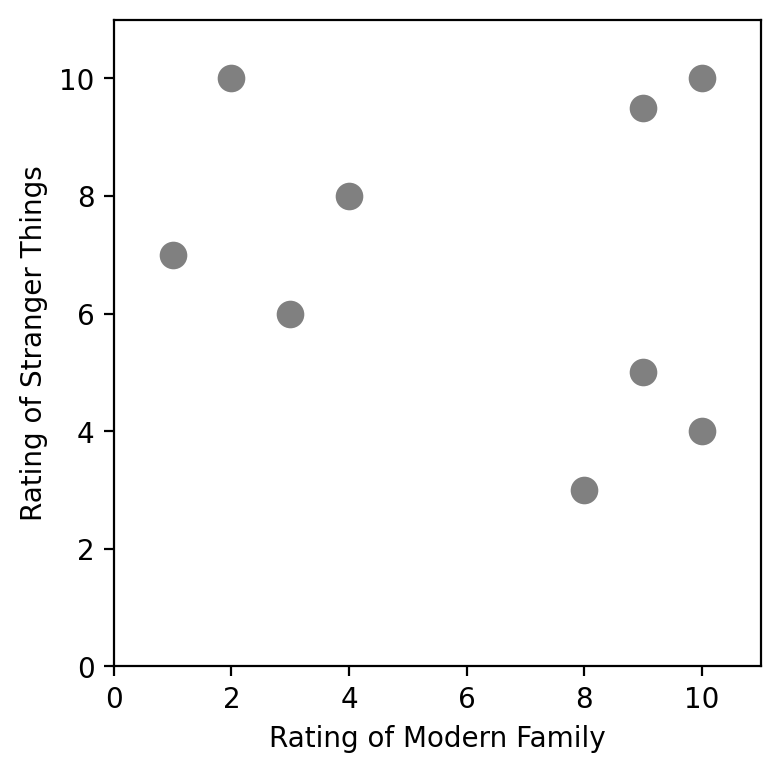

In [4]:
points = ratings.to_numpy()

def base_axes(ax):
    ax.set(xlabel='Rating of Modern Family',
           ylabel='Rating of Stranger Things',
           xlim=(0, 11), ylim=(0, 11), aspect='equal')

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(points[:, 0], points[:, 1], s=80, color='gray')
base_axes(ax)
plt.show()

- The eye sees three groups: fans of Stranger Things, fans of Modern
  Family, and fans of both. The service could recommend to each group what
  its members liked.
- **Clustering** puts each observation in a cluster, so that
  observations in the same cluster are close to each other. With two
  features we can see the clusters by eye. With thousands of features,
  such as the words of the Federalist Papers, we need an algorithm.

### Place centroids and give each customer to the nearest one

One way to define $k$ clusters: choose $k$ centers, the **centroids**, and
give every customer to the nearest centroid. Two small functions do the
arithmetic. `nearest` returns, for each point, the index of the closest
center. `inertia` adds up the squared distance from each point to its
center.

In [5]:
def nearest(points, centers):
    gaps = points[:, None, :] - centers[None, :, :]
    return (gaps ** 2).sum(axis=2).argmin(axis=1)

def inertia(points, centers, groups):
    return sum(((points[groups == j] - centers[j]) ** 2).sum()
               for j in range(len(centers)))

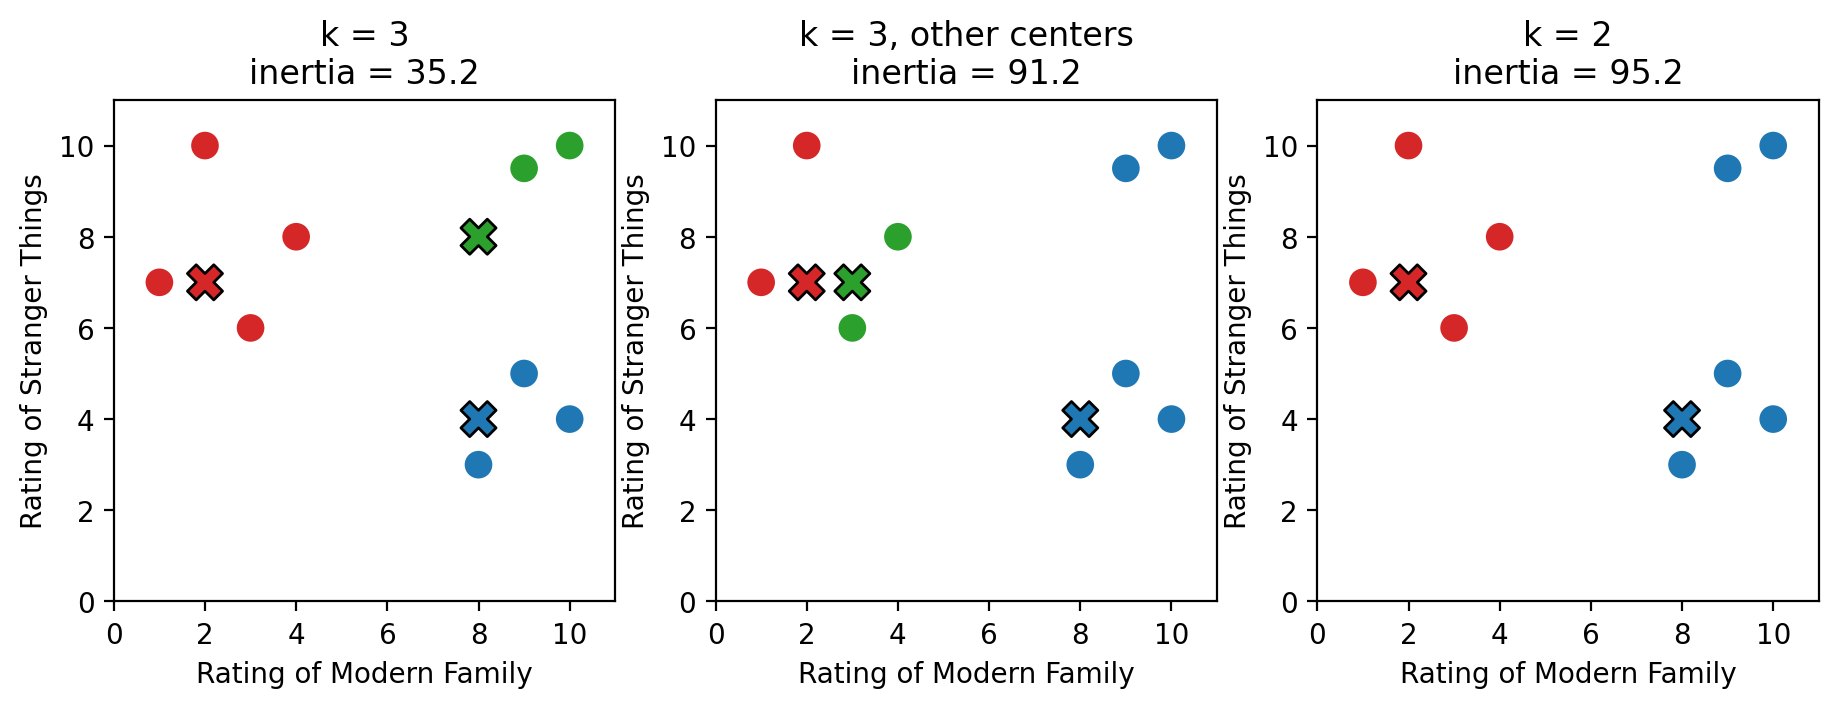

In [6]:
colors = np.array(['C3', 'C0', 'C2', 'C1', 'C4'])

def draw(centers, ax, title, groups=None, lines=False):
    centers = np.asarray(centers, dtype=float)
    if groups is None:
        groups = nearest(points, centers)
    ax.scatter(points[:, 0], points[:, 1], s=80, c=colors[groups])
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=160,
               c=colors[:len(centers)], edgecolor='black')
    if lines:
        for p, g in zip(points, groups):
            ax.plot([p[0], centers[g, 0]], [p[1], centers[g, 1]],
                    color='gray', lw=0.8)
    base_axes(ax)
    score = inertia(points, centers, groups)
    ax.set_title(f'{title}\ninertia = {score:.1f}')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
draw([[2, 7], [8, 4], [8, 8]], axes[0], 'k = 3')
draw([[2, 7], [8, 4], [3, 7]], axes[1], 'k = 3, other centers')
draw([[2, 7], [8, 4]], axes[2], 'k = 2')
plt.show()

- Each X is a centroid; each customer takes the color of the nearest one.
  The left placement colors the points the way the eye does. The middle
  one has three centers too, but two of them sit in the same cluster.
- **Inertia** scores a placement: the sum over customers of the squared
  distance to the customer's centroid. Smaller is tighter. The left
  placement has the smallest inertia of the three.

### ❓ Question

What is the inertia if $k = 9$, one centroid per customer?

<details><summary>Answer</summary>

**Zero.** Every customer sits on a centroid. Inertia falls as $k$ grows,
and one centroid per point drives it to zero. So we cannot choose $k$ by
making inertia as small as possible. We fix $k$ first, then make inertia
as small as possible for that $k$.

</details>

### The k-means algorithm: assign, then update

No formula gives the centroids with the smallest inertia. **k-means**
(Lloyd's algorithm) reaches a good placement by repeating two steps:

0. Start with $k$ centers, chosen at random.
1. **Assign** each point to its nearest center.
2. **Update** each center to the mean of its points.
3. Repeat 1 and 2 until no point changes cluster.

The loop below runs the two steps on two centers placed by hand at (2, 5)
and (8, 10), and prints the inertia after each step.

In [7]:
centers = np.array([[2, 5], [8, 10]], dtype=float)
for step in range(1, 5):
    groups = nearest(points, centers)
    print(f'step {step}  assign  inertia '
          f'{inertia(points, centers, groups):.2f}')
    new_centers = np.array([points[groups == j].mean(axis=0)
                            for j in range(len(centers))])
    print(f'step {step}  update  inertia '
          f'{inertia(points, new_centers, groups):.2f}')
    if np.allclose(new_centers, centers):
        break
    centers = new_centers
centers.round(2)

step 1  assign  inertia 156.25
step 1  update  inertia 85.19
step 2  assign  inertia 70.65
step 2  update  inertia 58.35
step 3  assign  inertia 58.35
step 3  update  inertia 58.35


array([[2.5 , 7.75],
       [9.2 , 6.3 ]])

- Inertia falls at every half step, from 156 to 85 to 71 to 58, and the
  loop stops when an update moves nothing.
- Inertia cannot rise. Moving a point to its nearest center cannot raise
  that point's distance, and the mean of a cluster is the point with the
  smallest sum of squared distances to the cluster.

### Draw each step of k-means

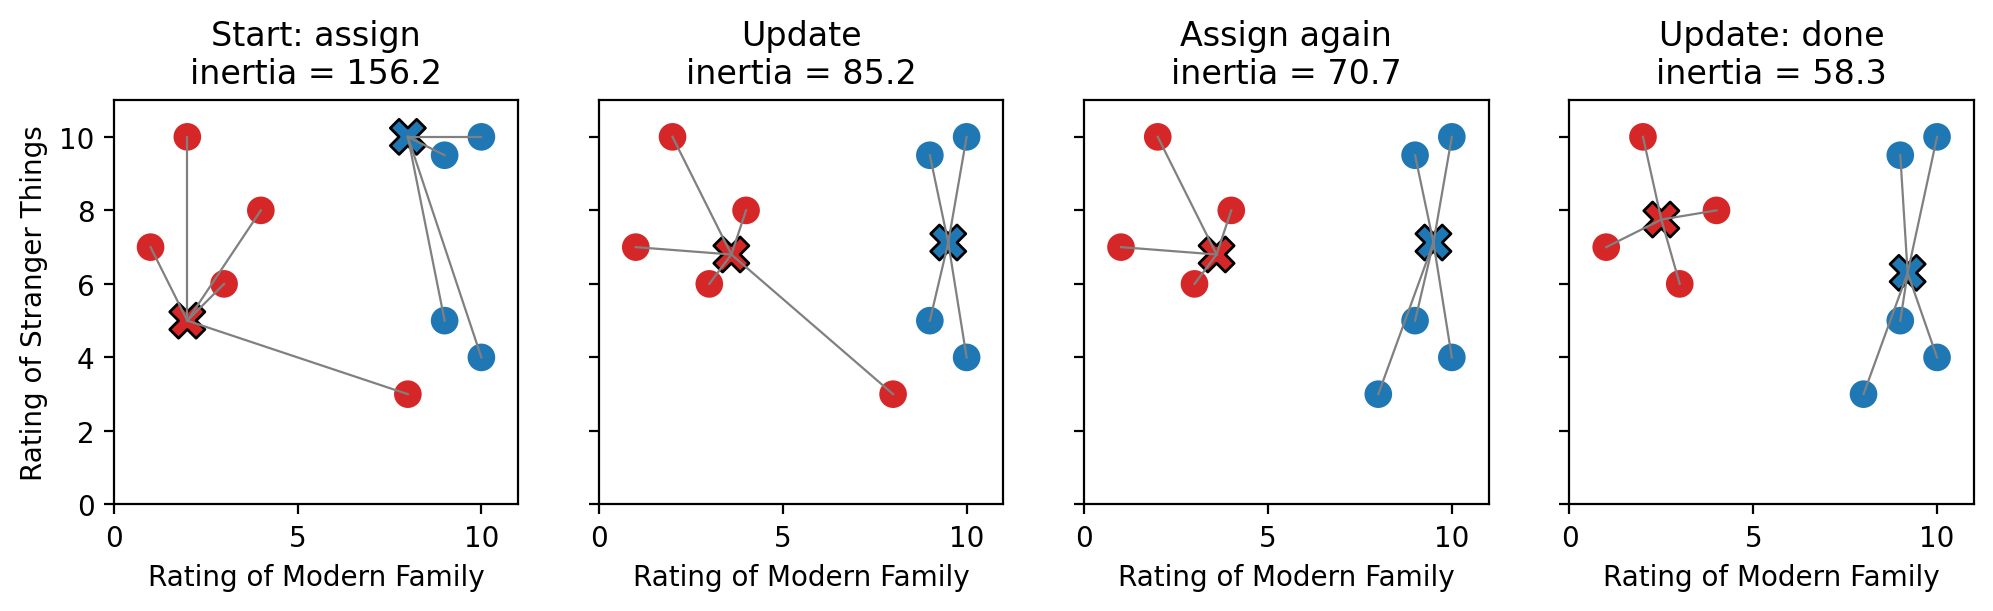

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
start = np.array([[2, 5], [8, 10]], dtype=float)
g1 = nearest(points, start)
draw(start, axes[0], 'Start: assign', g1, lines=True)
c1 = np.array([points[g1 == j].mean(axis=0) for j in range(2)])
draw(c1, axes[1], 'Update', g1, lines=True)
g2 = nearest(points, c1)
draw(c1, axes[2], 'Assign again', g2, lines=True)
c2 = np.array([points[g2 == j].mean(axis=0) for j in range(2)])
draw(c2, axes[3], 'Update: done', g2, lines=True)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.show()

- One customer, the one at (8, 3), changes cluster at the second
  assignment. After the second update nothing changes, so the algorithm
  stops.
- The gray lines are the distances that inertia squares and adds up.

### Run k-means from five random starts

`KMeans` with `n_init=1` runs the algorithm once from random starting
centers. `random_state` fixes the random numbers, so five values give
five different starts.

In [9]:
for seed in range(5):
    km = KMeans(n_clusters=3, n_init=1, random_state=seed).fit(points)
    print(seed, km.labels_, round(km.inertia_, 2))

0 [1 1 1 1 0 0 0 2 2] 18.38
1 [2 0 2 0 1 1 1 1 1] 51.1
2 [0 0 0 0 1 1 1 2 2] 18.38
3 [1 1 1 1 0 0 0 2 2] 18.38
4 [1 1 1 1 2 2 2 0 0] 18.38


- Four starts reach inertia 18.4, the three groups the eye sees. Seed 1
  stops at 51.1: a **local minimum**, where no single step improves the
  placement but a different start would.
- With `n_init=20`, `KMeans` runs the algorithm 20 times from different
  starts and keeps the run with the smallest inertia.

### Fit k-means with `KMeans`

Create the model, fit it, and read its attributes. `fit` takes `X`
only: there is no `y`.

In [10]:
km = KMeans(n_clusters=3, n_init=20, random_state=42)
km.fit(points)
print(km.labels_)
print(km.cluster_centers_.round(2))
print(round(km.inertia_, 2))

[1 1 1 1 2 2 2 0 0]
[[9.5  9.75]
 [2.5  7.75]
 [9.   4.  ]]
18.38


In [11]:
km.predict([[6, 6]]), km.fit_predict(points)

(array([2], dtype=int32), array([1, 1, 1, 1, 2, 2, 2, 0, 0], dtype=int32))

- `labels_` is the cluster of each observation, numbered 0 to $k-1$. The
  numbers carry no meaning and can change between runs.
- `cluster_centers_` has one row per centroid; `inertia_` is the final
  score.
- `predict` gives the nearest centroid of a new customer;
  `fit_predict` fits and returns `labels_` in one call.

### Choose $k$ with the elbow and the silhouette

Fit $k$ from 1 to 8 and record the inertia. A second score, the
**silhouette** of a point, compares $a$, its mean distance to the points
of its own cluster, with $b$, its mean distance to the points of the
nearest other cluster: $(b - a) / \max(a, b)$, from $-1$ to $1$. Near 1,
the point sits well inside its cluster. `silhouette_score` averages it over the
points.

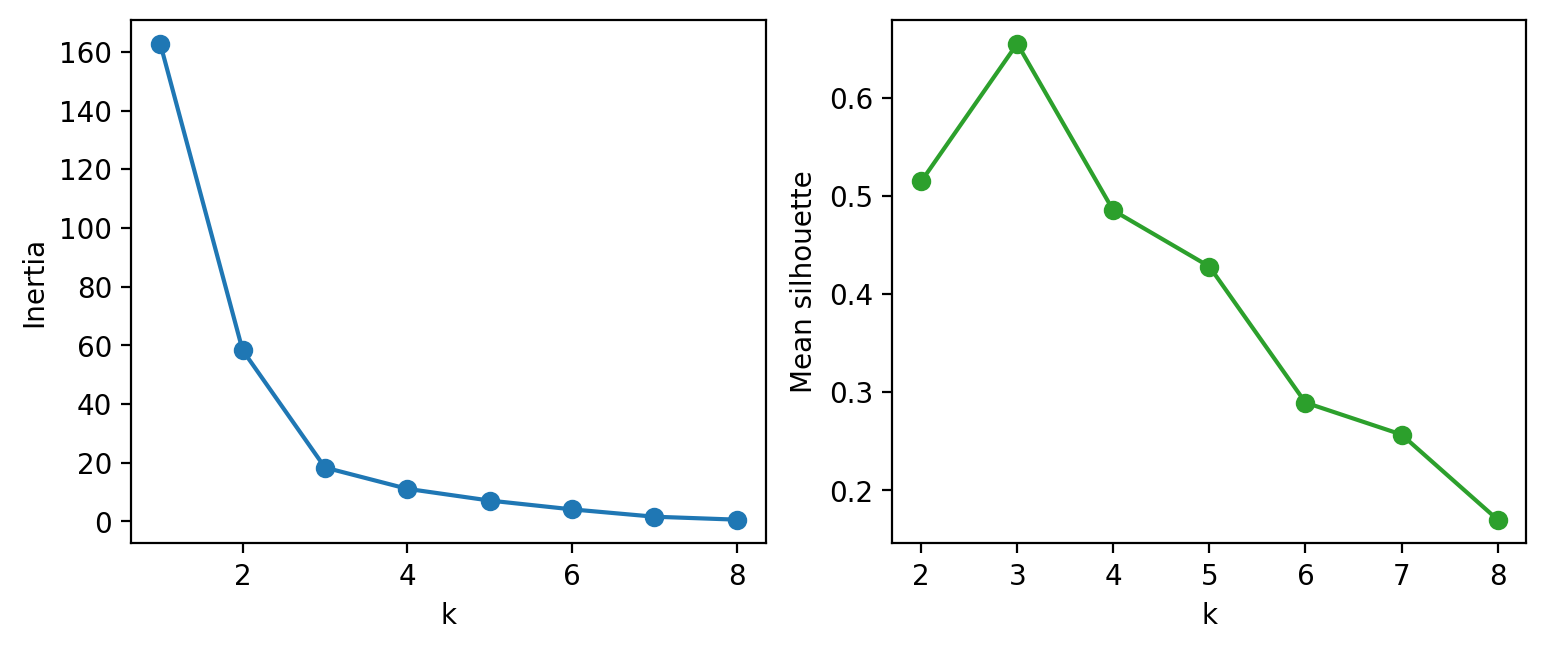

In [12]:
ks = range(1, 9)
inertias = [KMeans(n_clusters=k, n_init=20, random_state=42)
            .fit(points).inertia_ for k in ks]
silhouettes = [silhouette_score(points, KMeans(
    n_clusters=k, n_init=20, random_state=42).fit_predict(points))
    for k in range(2, 9)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(ks, inertias, marker='o')
axes[0].set(xlabel='k', ylabel='Inertia')
axes[1].plot(range(2, 9), silhouettes, marker='o', color='C2')
axes[1].set(xlabel='k', ylabel='Mean silhouette')
plt.show()

- Inertia falls fast up to $k = 3$ and slowly after it: the **elbow**.
  Past the elbow, one more cluster lowers inertia only a little.
- The silhouette is highest at $k = 3$, 0.66. Both scores agree with the
  eye here. On real data they often disagree, and $k$ can also come from
  the question: a shirt maker who sells five sizes needs five clusters.

<div class="alert alert-info">

**Key idea.** k-means makes the inertia small for a chosen $k$ by
repeating assign and update. The result depends on the features, their
scale, $k$, and the start. The cluster numbers are arbitrary. We usually
choose $k$ with the elbow method or the silhouette.

</div>

## Agglomerative clustering: merge the two closest clusters

A second way to build clusters, with no centroids:

1. Start with every point as its own cluster.
2. Merge the two closest clusters.
3. Repeat until $k$ clusters remain.

"Closest" needs a rule, the **linkage**: the distance between the nearest
pair of points (single), the farthest pair (complete), or the mean over
pairs (average). The default, Ward, merges the pair of clusters whose
merger raises the inertia least.

In [13]:
agg = AgglomerativeClustering(n_clusters=3).fit(points)
print(agg.labels_)
km3 = KMeans(n_clusters=3, n_init=20, random_state=42)
print(km3.fit_predict(points))

[0 0 0 0 1 1 1 2 2]
[1 1 1 1 2 2 2 0 0]


- On the nine customers the two methods form the same three clusters.
  Only the arbitrary cluster numbers differ.

### Compare k-means and agglomerative clustering on two moons

`make_moons` draws 300 points in two interlocking half circles. k-means
draws a straight boundary halfway between two centroids; single-linkage
agglomerative clustering follows chains of near neighbors.

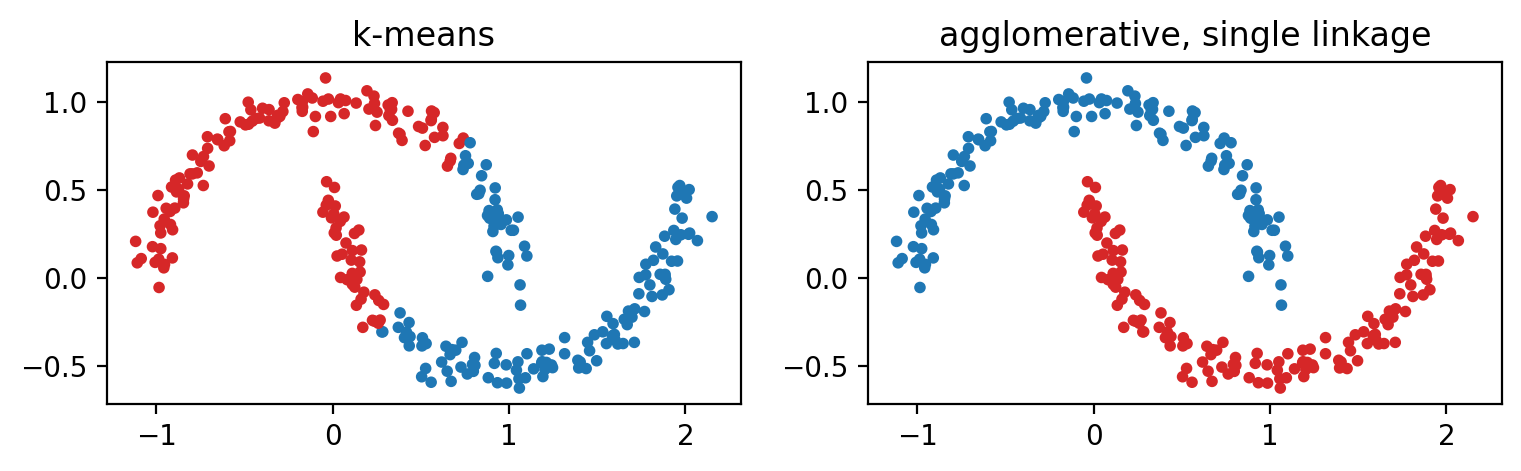

In [14]:
moons, _ = make_moons(n_samples=300, noise=0.06, random_state=0)
km_m = KMeans(n_clusters=2, n_init=20, random_state=42)
agg_m = AgglomerativeClustering(n_clusters=2, linkage='single')
results = {'k-means': km_m.fit_predict(moons),
           'agglomerative, single linkage': agg_m.fit_predict(moons)}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (title, groups) in zip(axes, results.items()):
    ax.scatter(moons[:, 0], moons[:, 1], s=10, c=colors[groups])
    ax.set(title=title, aspect='equal')
plt.show()

- k-means expects round clusters of similar size around a center, so it
  cuts each moon in two. Single linkage follows each moon.
- No method is best for all data. The
  [scikit-learn clustering page](https://scikit-learn.org/stable/modules/clustering.html)
  compares ten methods on six toy datasets.

## Part 2: clustering the Federalist Papers

### Build the TF-IDF matrix of lecture 13

- In lecture 13, a model trained on the author labels told Hamilton's
  papers from Madison's. Now we hide the labels and run k-means on the
  same TF-IDF matrix.
- Three men wrote the papers. Without the author labels, do three
  clusters find the three writers?

In [15]:
rows = []
for n in range(1, 86):
    path = RAW / 'federalist' / f'fp{n:02d}.txt'
    rows.append({'essay': n,
                 'text': path.read_text(encoding='utf-8')})
essays = pd.DataFrame(rows)

authors = {
    'Hamilton': ([1, 6, 7, 8, 9, 11, 12, 13, 15, 16, 17]
                 + list(range(21, 37)) + [59, 60, 61]
                 + list(range(65, 86))),
    'Madison': [10, 14] + list(range(37, 49)),
    'Jay': [2, 3, 4, 5, 64],
    'Joint': [18, 19, 20],
    'Disputed': list(range(49, 59)) + [62, 63],
}
label = {n: author for author, ns in authors.items() for n in ns}
essays['author'] = essays['essay'].map(label)

vectorizer = TfidfVectorizer(min_df=2)
tfidf = vectorizer.fit_transform(essays['text'])
terms = vectorizer.get_feature_names_out()
tfidf.shape

(85, 5424)

- 85 papers and 5,424 words. As in lecture 13, we keep the stop words:
  common words such as `upon` and `on` help tell the writers apart.
- `TfidfVectorizer` scales each paper's weights to length 1, so long
  papers do not dominate the distance.

### Fit three clusters from many starts

With 5,424 columns, k-means can stop at many local minima. Run it three
times with 20 starts each, as in Part 1, and print the inertia and the
cluster sizes.

In [16]:
for seed in range(3):
    km_seed = KMeans(n_clusters=3, n_init=20, random_state=seed)
    km_seed.fit(tfidf)
    sizes = np.bincount(km_seed.labels_)
    print(seed, round(km_seed.inertia_, 3), sizes)

0 11.381 [24  4 57]
1 11.353 [ 5 45 35]
2 11.315 [30  5 50]


- Each seed stops at a different inertia with different cluster sizes:
  three different local minima.
- `n_init=1000` keeps the best of 1,000 starts. With 85 papers this takes
  about a second.

### Compare three clusters with the authors

In [17]:
km_text = KMeans(n_clusters=3, n_init=1000, random_state=42)
essays['cluster'] = km_text.fit_predict(tfidf)
print(round(km_text.inertia_, 3),
      round(silhouette_score(tfidf, essays['cluster']), 3))
pd.crosstab(essays['author'], essays['cluster'])

11.296 0.035


cluster,0,1,2
author,,,
Disputed,0,12,0
Hamilton,51,0,0
Jay,0,0,5
Joint,0,3,0
Madison,1,13,0


- The inertia is 11.296, lower than all three runs with 20 starts.
- One cluster holds Jay's five papers and nothing else. One holds
  Hamilton's 51 papers and one of Madison's. The third holds Madison's
  other 13, all 12 disputed papers, and the 3 joint papers.
- The silhouette is 0.035, so the three clusters sit close together.

### Plot the papers on pairs of words

Each panel plots the 85 papers on two words of the matrix, colored by
cluster. Black circles mark the 12 disputed papers. The pairs are two
style words from lecture 13, two words that separate Jay's cluster, and
two subject words.

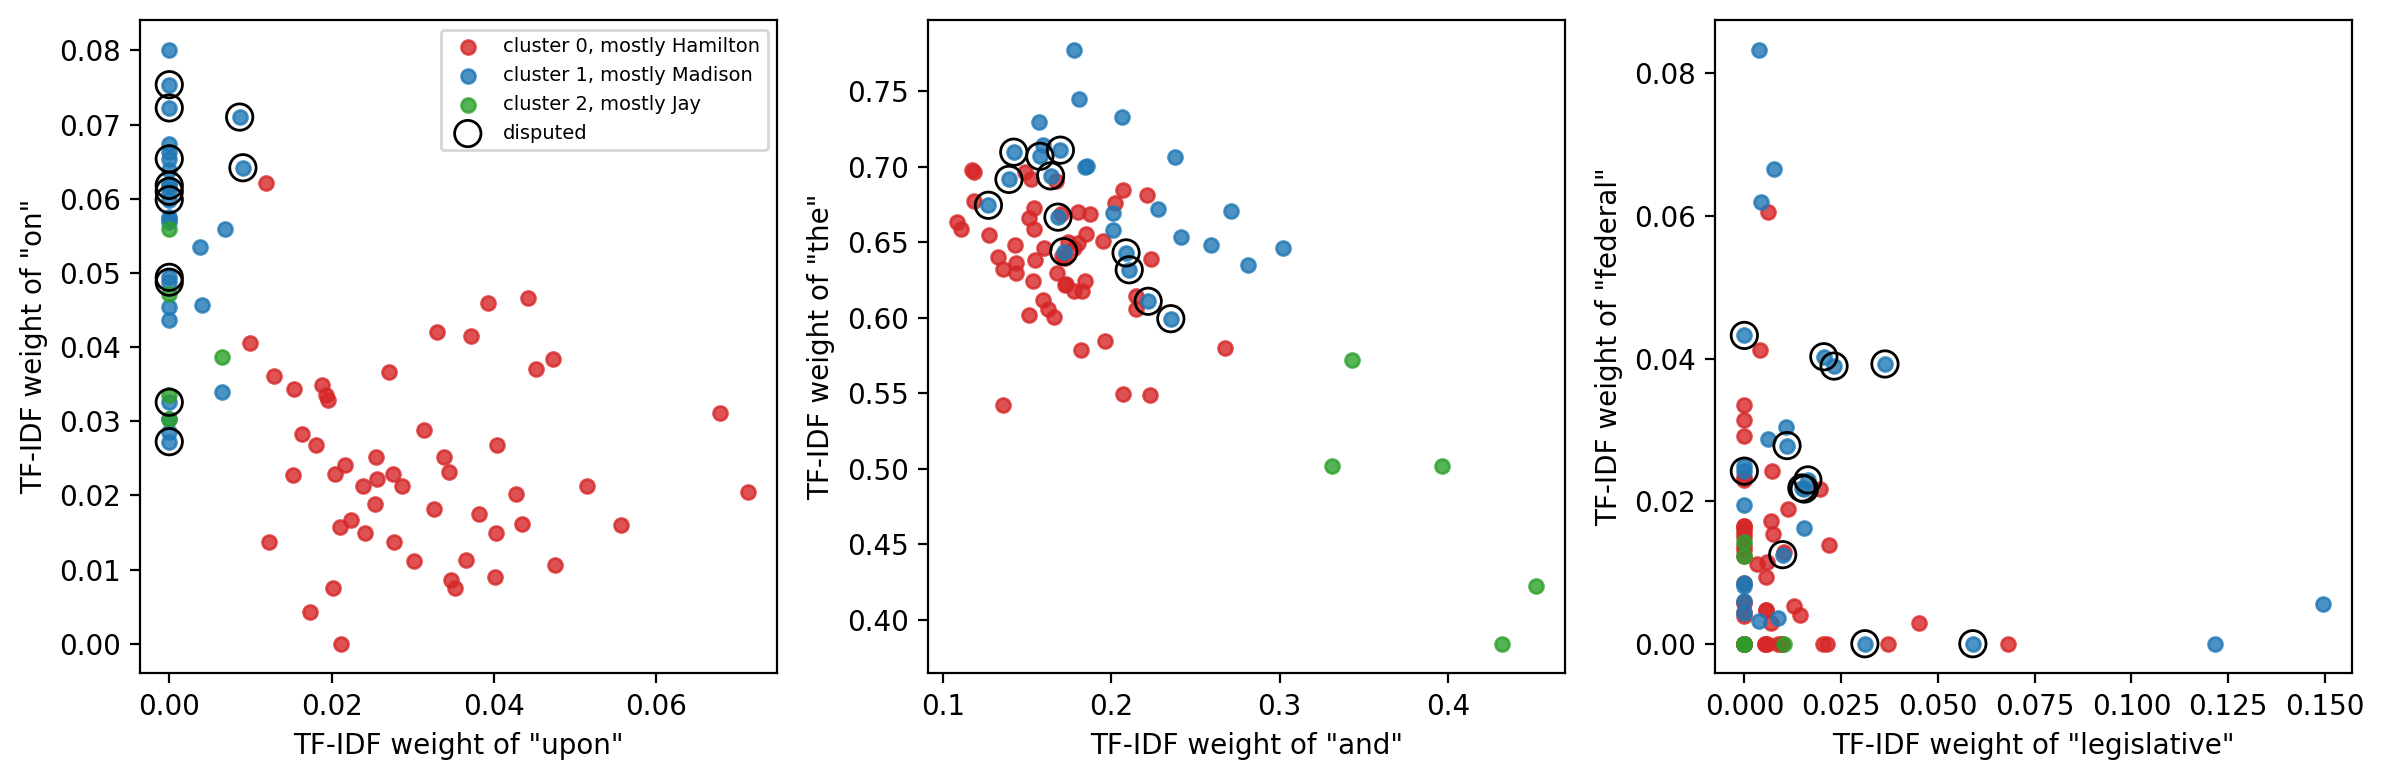

author
Disputed    10
Hamilton     0
Jay          4
Joint        1
Madison     11
Name: upon, dtype: int64

In [18]:
dense = pd.DataFrame(tfidf.toarray(), columns=terms)
names = pd.crosstab(essays['author'], essays['cluster']).idxmax()
disputed = essays['author'] == 'Disputed'
pairs = [('upon', 'on'), ('and', 'the'), ('legislative', 'federal')]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (x, y) in zip(axes, pairs):
    for j in range(3):
        in_j = essays['cluster'] == j
        ax.scatter(dense.loc[in_j, x], dense.loc[in_j, y], s=25,
                   color=colors[j], alpha=0.8,
                   label=f'cluster {j}, mostly {names[j]}')
    ax.scatter(dense.loc[disputed, x], dense.loc[disputed, y], s=90,
               facecolors='none', edgecolors='black', label='disputed')
    ax.set(xlabel=f'TF-IDF weight of "{x}"',
           ylabel=f'TF-IDF weight of "{y}"')
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
(dense['upon'] == 0).groupby(essays['author']).sum()

- `upon` and `on`: Hamilton's cluster sits to the right, and Madison's
  sits to the left and higher on `on`. The disputed papers sit with
  Madison's. All 51 of Hamilton's papers use `upon`; 11 of Madison's 14
  and 10 of the 12 disputed papers never do.
- `and` and `the`: Jay's five papers stand apart. They use `and` more
  than any other paper, and most of them use `the` less.
- `legislative` and `federal`: the clusters overlap. No single pair of
  words separates the clusters; k-means uses all 5,424 words at once.

## Part 3: clustering the House

### Plot the 119th House on its two NOMINATE scores

- Recall the [Voteview](https://voteview.com/) data from earlier
  lectures.
- Political scientists measure each member's ideology from roll-call
  votes. The best-known measure is the NOMINATE score, which has two
  dimensions. Party is never an input.
- The first dimension runs from liberal to conservative.
- The second dimension captures cross-cutting issues, such as regional
  or social ones, that divide members apart from the left-right split.
- If we hide the party labels, do the two scores still split the House
  into two clusters?
- The file also holds the Senate and the presidents. Keep the 119th
  House, the two parties (`party_code` 100 and 200), and the members with
  both scores.

In [19]:
members_all = pd.read_csv(VOTEVIEW / 'HSall_members.csv.gz')
house_119 = members_all[(members_all['congress'] == 119)
                        & (members_all['chamber'] == 'House')
                        & members_all['party_code'].isin([100, 200])]
house_119 = house_119.dropna(subset=['nominate_dim1',
                                     'nominate_dim2']).copy()
house_119['party'] = house_119['party_code'].map({100: 'Democrat',
                                                  200: 'Republican'})
positions = house_119[['nominate_dim1', 'nominate_dim2']]
print(members_all.shape)
house_119['party'].value_counts()

(51064, 22)


party
Republican    227
Democrat      222
Name: count, dtype: int64

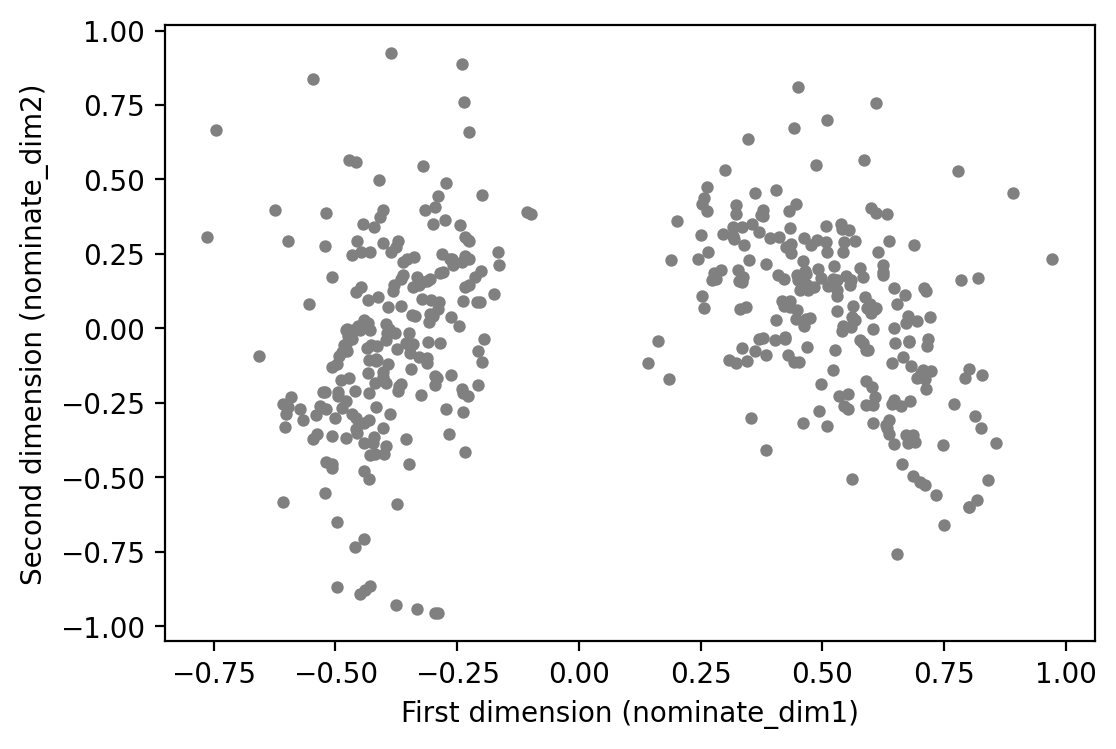

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(positions['nominate_dim1'], positions['nominate_dim2'], s=12,
           color='gray')
ax.set(xlabel='First dimension (nominate_dim1)',
       ylabel='Second dimension (nominate_dim2)')
plt.show()

- The 119th House was still in session when we saved the file on
  2026-10-27, so its scores use the votes up to that day.
- The points form two clouds with a gap near zero on the first
  dimension, so the eye says $k = 2$.

### Compare two clusters with party

Fit k-means on the two score columns. Party is not an input;
`pd.crosstab` compares the clusters with party afterward.

In [21]:
km2 = KMeans(n_clusters=2, n_init=20, random_state=42)
house_119['cluster'] = km2.fit_predict(positions)
pd.crosstab(house_119['party'], house_119['cluster'])

cluster,0,1
party,,
Democrat,0,222
Republican,227,0


- All 449 members sit in the cluster of their party.
- The scores come from votes, so in 2025 party and voting line up
  exactly. The algorithm found two clusters; we named them after the
  parties.

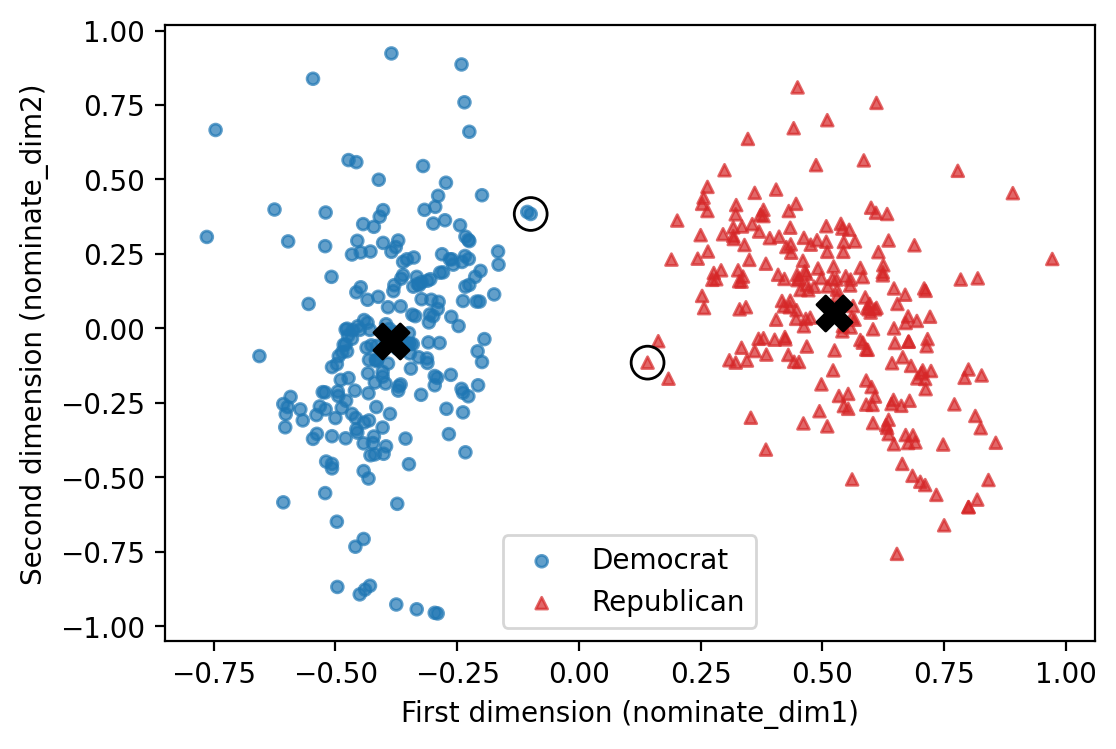

[[ 0.52  0.05]
 [-0.39 -0.04]]


,bioname,state_abbrev,nominate_dim1,nominate_dim2
50944,"PEREZ, Marie Gluesenkamp",WA,-0.099,0.384
50849,"FITZPATRICK, Brian K.",PA,0.141,-0.115


In [22]:
dems = house_119[house_119['party'] == 'Democrat']
reps = house_119[house_119['party'] == 'Republican']
edge = pd.concat([dems.nlargest(1, 'nominate_dim1'),
                  reps.nsmallest(1, 'nominate_dim1')])
markers = {'Democrat': 'o', 'Republican': '^'}
fig, ax = plt.subplots(figsize=(6, 4))
for party, marker in markers.items():
    part = house_119[house_119['party'] == party]
    ax.scatter(part['nominate_dim1'], part['nominate_dim2'], s=18,
               marker=marker, c=colors[part['cluster']], alpha=0.7,
               label=party)
ax.scatter(*km2.cluster_centers_.T, marker='X', s=160, c='black')
ax.scatter(edge['nominate_dim1'], edge['nominate_dim2'], s=140,
           facecolors='none', edgecolors='black')
ax.set(xlabel='First dimension (nominate_dim1)',
       ylabel='Second dimension (nominate_dim2)')
ax.legend()
plt.show()
print(km2.cluster_centers_.round(2))
edge[['bioname', 'state_abbrev', 'nominate_dim1', 'nominate_dim2']]

- Color is the cluster and shape is the party. The two circled members
  sit closest to the center: Marie Gluesenkamp Perez, a Democrat from
  Washington, at $-0.10$ on the first dimension, and Brian Fitzpatrick, a
  Republican from Pennsylvania, at 0.14. No member sits between them.
- The black X marks are the centroids, at about $-0.39$ and $0.52$ on
  the first dimension.

### Check $k$ with inertia and the silhouette

Is two the right number of clusters? Compute inertia and the silhouette
for $k$ from 1 to 6.

In [23]:
for k in range(1, 7):
    km_k = KMeans(n_clusters=k, n_init=20, random_state=42)
    km_k.fit(positions)
    sil = silhouette_score(positions, km_k.labels_) if k > 1 else np.nan
    print(f'k = {k}   inertia {km_k.inertia_:6.1f}   '
          f'silhouette {sil:.3f}')

k = 1   inertia  145.9   silhouette nan
k = 2   inertia   52.0   silhouette 0.596
k = 3   inertia   36.7   silhouette 0.512
k = 4   inertia   24.0   silhouette 0.450
k = 5   inertia   19.6   silhouette 0.443
k = 6   inertia   15.9   silhouette 0.407


- The elbow is at $k = 2$, and the silhouette is highest there, at 0.60.

<div class="alert alert-info">

**Key idea.** The features define the distance, and the distance defines
the clusters.

</div>

## Part 4: principal component analysis

### Where do the ideology scores come from?

- Part 3 clustered members on two numbers, `nominate_dim1` and
  `nominate_dim2`.
- The 118th House (2023 to 2024) took 1,235 recorded votes. NOMINATE
  turns each member's votes into two numbers.
- How can we turn 1,235 votes into a few useful scores?
- **Dimensionality reduction** turns data with many columns (such as
  1,235 votes) into data with a few columns, while preserving as much of
  the structure as possible.
- **Principal component analysis** (PCA) is the most common method. Part
  5 runs it on the 1,235 votes and compares the result with NOMINATE.
- First, a toy example shows the idea.

### Ten customers rate two crime dramas

Ten customers rated *Breaking Bad* and its prequel *Better Call Saul*
from 1 to 10. The ratings are made up for the illustration.

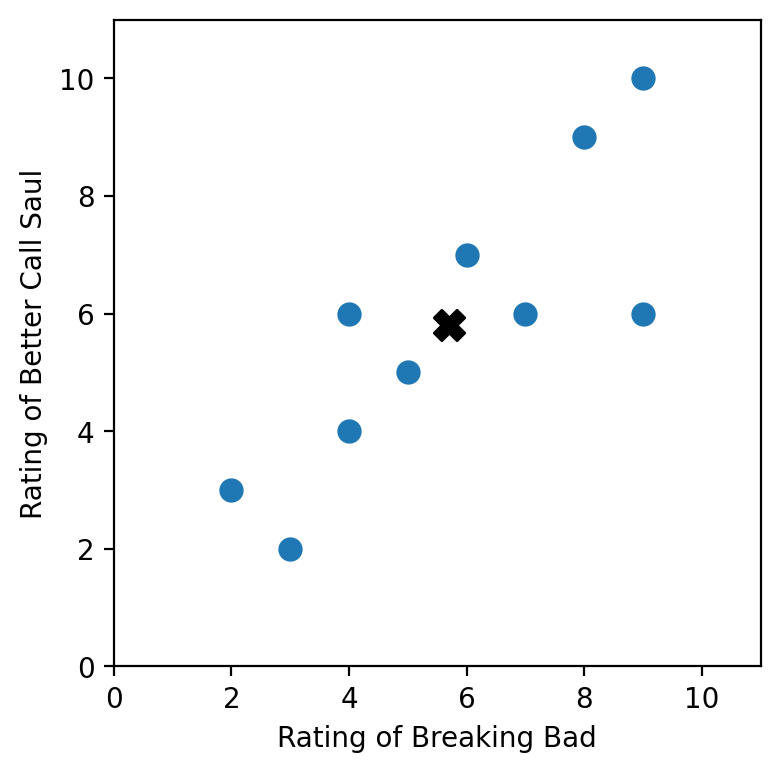

[5.7 5.8] 0.83


In [24]:
shows = pd.DataFrame({
    'breaking_bad': [2, 3, 4, 4, 5, 6, 7, 8, 9, 9],
    'better_call_saul': [3, 2, 4, 6, 5, 7, 6, 9, 6, 10]})
X_shows = shows.to_numpy(dtype=float)
center = X_shows.mean(axis=0)

def show_axes(ax):
    ax.set(xlabel='Rating of Breaking Bad',
           ylabel='Rating of Better Call Saul',
           xlim=(0, 11), ylim=(0, 11), aspect='equal')

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(X_shows[:, 0], X_shows[:, 1], s=60, color='C0')
ax.scatter(*center, marker='X', s=120, color='black')
show_axes(ax)
plt.show()
print(center, shows.corr().round(2).iloc[0, 1])

- A customer who rates one show high usually rates the other high too:
  the correlation is 0.83. The black X is the center of the cloud, the
  mean of each column (5.7, 5.8).
- The two columns carry almost the same information: how much the
  customer likes this kind of show. If we had to describe each customer
  with one number, which number would leave the least unexplained?

### Summarize each customer with one number: a position on a line

Draw a line through the center. Move each customer to the nearest point
on the line, along a segment at right angles to the line. The customer's
position along the line, measured from the center, is the one number.

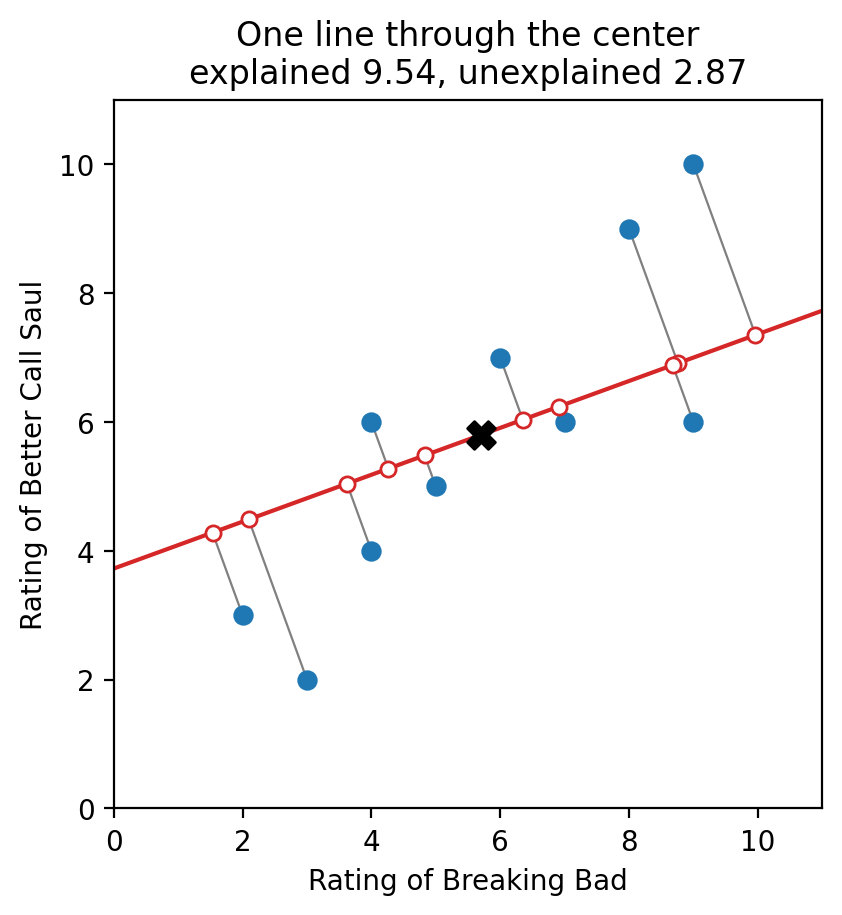

In [25]:
def unit(angle):
    # A direction of length 1 at the given angle, in degrees.
    return np.array([np.cos(np.radians(angle)),
                     np.sin(np.radians(angle))])

def project(direction):
    positions = (X_shows - center) @ direction
    on_line = center + np.outer(positions, direction)
    return positions, on_line

def explained_unexplained(direction):
    # Variances: sums of squares divided by n - 1.
    positions, on_line = project(direction)
    n = len(X_shows)
    return ((positions ** 2).sum() / (n - 1),
            ((X_shows - on_line) ** 2).sum() / (n - 1))

def draw_line(ax, direction, title):
    positions, on_line = project(direction)
    ends = center + np.outer([-9, 9], direction)
    ax.plot(ends[:, 0], ends[:, 1], color='C3', lw=1.5)
    for p, q in zip(X_shows, on_line):
        ax.plot([p[0], q[0]], [p[1], q[1]], color='gray', lw=0.8)
    ax.scatter(X_shows[:, 0], X_shows[:, 1], s=40, color='C0', zorder=3)
    ax.scatter(on_line[:, 0], on_line[:, 1], s=30, color='white',
               edgecolors='C3', zorder=4)
    ax.scatter(*center, marker='X', s=100, color='black', zorder=5)
    explained, unexplained = explained_unexplained(direction)
    show_axes(ax)
    ax.set_title(f'{title}\nexplained {explained:.2f}, '
                 f'unexplained {unexplained:.2f}')

fig, ax = plt.subplots(figsize=(4.6, 4.6))
draw_line(ax, unit(20), 'One line through the center')
plt.show()

- Blue points are the customers. Open circles on the red line are the
  same customers, each described by one number.
- The **explained variance** is the variance of that one number: add up
  the squared positions along the red line and divide by $n - 1$.
- The **unexplained variance** is the rest: add up the squared lengths of
  the gray segments and divide by $n - 1$. It measures the part of each
  customer that the line leaves out.

### Compare three lines by the variance they explain

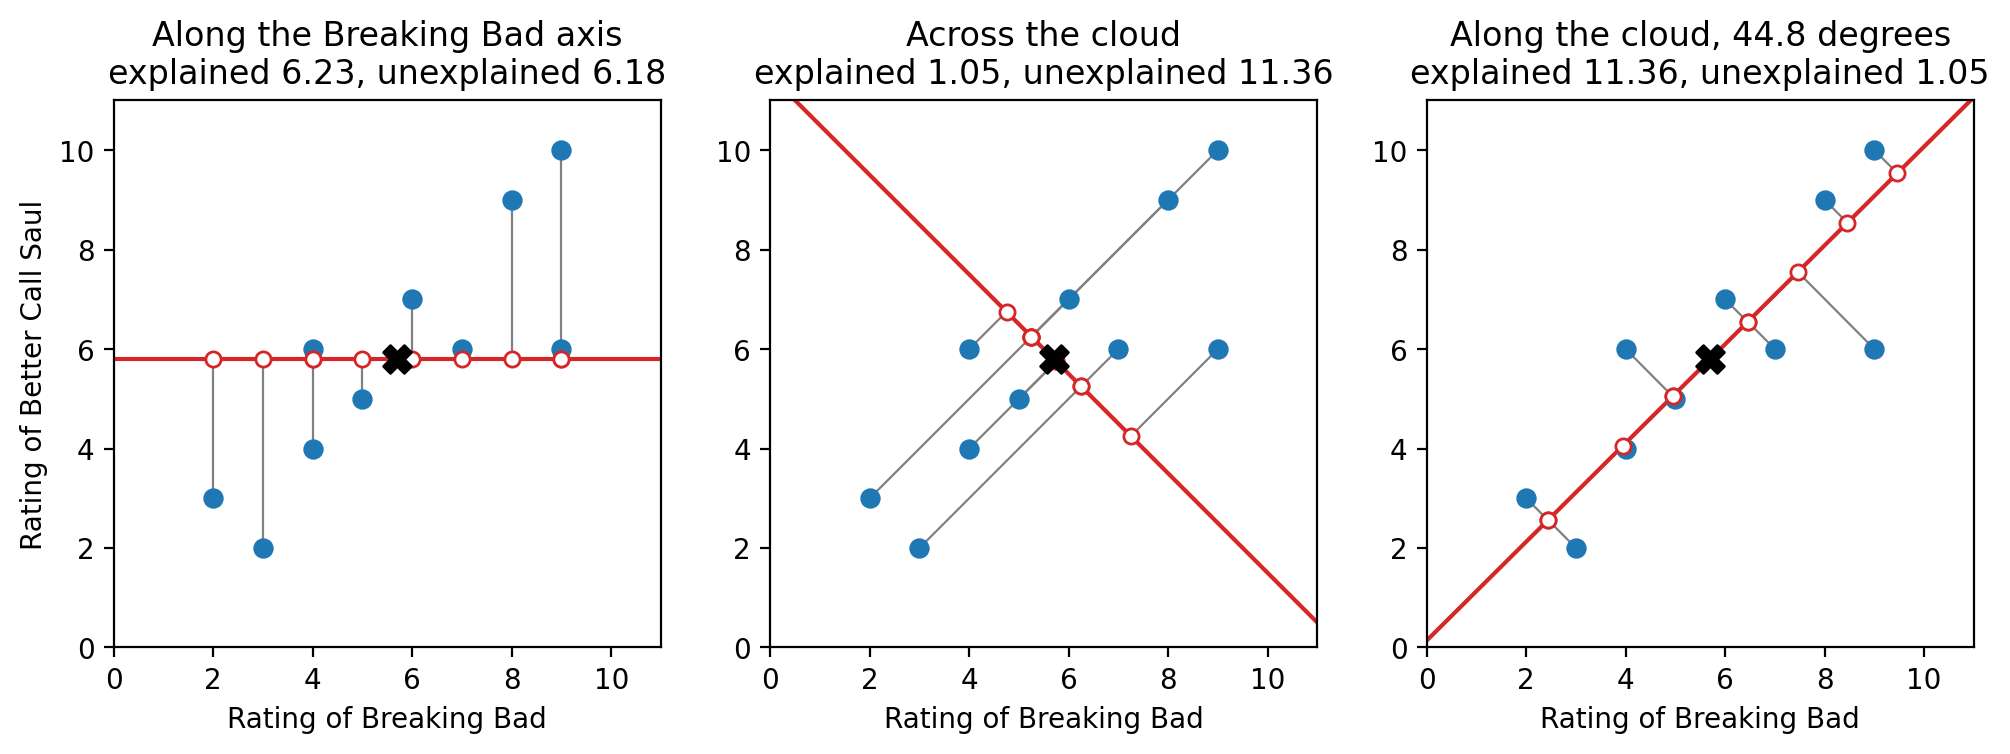

In [26]:
angles = np.arange(0, 180, 0.1).round(1)
explained_by_angle = np.array([explained_unexplained(unit(a))[0]
                               for a in angles])
best = angles[explained_by_angle.argmax()]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
draw_line(axes[0], unit(0), 'Along the Breaking Bad axis')
draw_line(axes[1], unit(135), 'Across the cloud')
draw_line(axes[2], unit(best), f'Along the cloud, {best} degrees')
for ax in axes[1:]:
    ax.set_ylabel('')
plt.show()

- Along the Breaking Bad axis, the one number is the Breaking Bad
  rating. It explains 6.23, the variance of Breaking Bad, and leaves 6.18
  unexplained, the variance of Better Call Saul.
- Across the cloud, the line explains only how much each customer's two
  ratings differ: 1.05. Along the cloud, it explains 11.36.
- In every panel, explained plus unexplained equals 12.41, the **total
  variance**: the variance of Breaking Bad plus the variance of Better
  Call Saul.
- For each customer, the squared distance to the center splits into a
  part along the line and a part across it (Pythagoras). So the line that
  explains the most variance also leaves the least unexplained.

### Turn the line through every angle

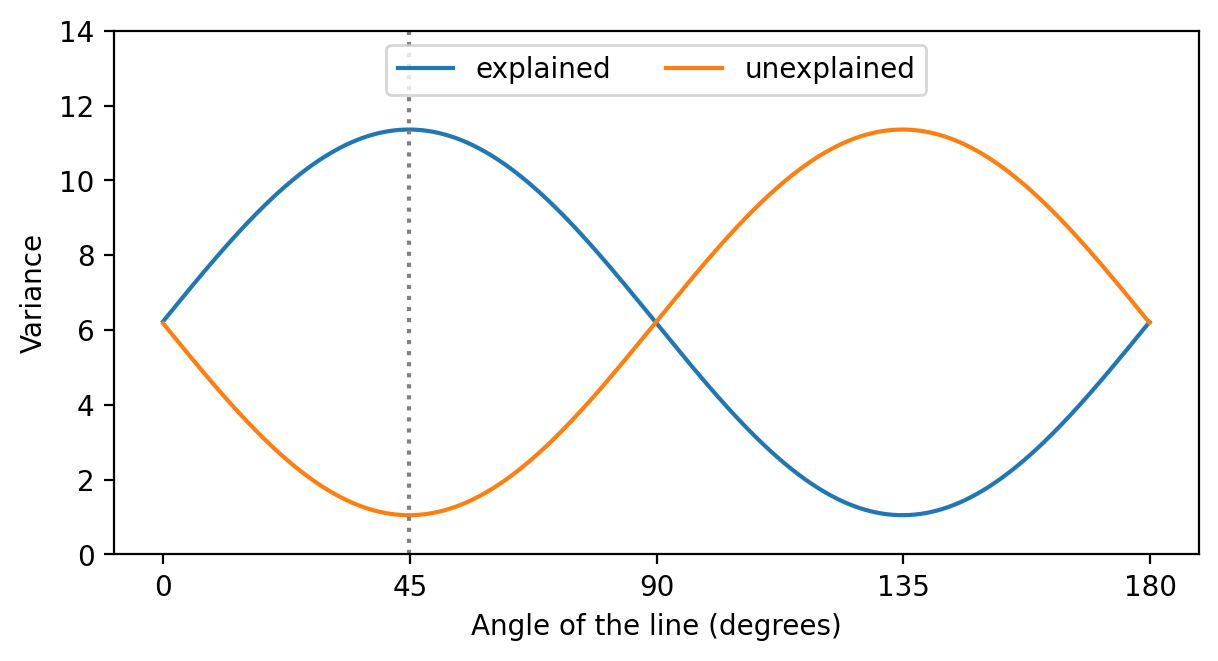

12.41 44.8 11.36


In [27]:
total = shows.var().sum()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(angles, explained_by_angle, label='explained')
ax.plot(angles, total - explained_by_angle, label='unexplained')
ax.axvline(best, color='gray', ls=':')
ax.set(xlabel='Angle of the line (degrees)',
       ylabel='Variance', xticks=range(0, 181, 45), ylim=(0, 14))
ax.legend(loc='upper center', ncol=2)
plt.show()
print(round(total, 2), best, round(explained_by_angle.max(), 2))

- As the line turns, the explained variance rises exactly as much as the
  unexplained variance falls.
- The explained variance peaks at 44.8 degrees, where the unexplained
  variance is smallest.
- That direction is the **first principal component** (PC1). A
  customer's position along it is the customer's **score** on PC1.

### ❓ Question

Lecture 13 fitted a line by least squares. Is PC1 the same line as the
regression of the Better Call Saul rating on the Breaking Bad rating?

<details><summary>Answer</summary>

**No.** Least squares makes the **vertical** distances small: it treats
Better Call Saul as the outcome and Breaking Bad as the predictor.

PCA makes the distances **at right angles (90 degrees)** to the line
small, and it treats the two columns the same way: there is no outcome
variable.

</details>

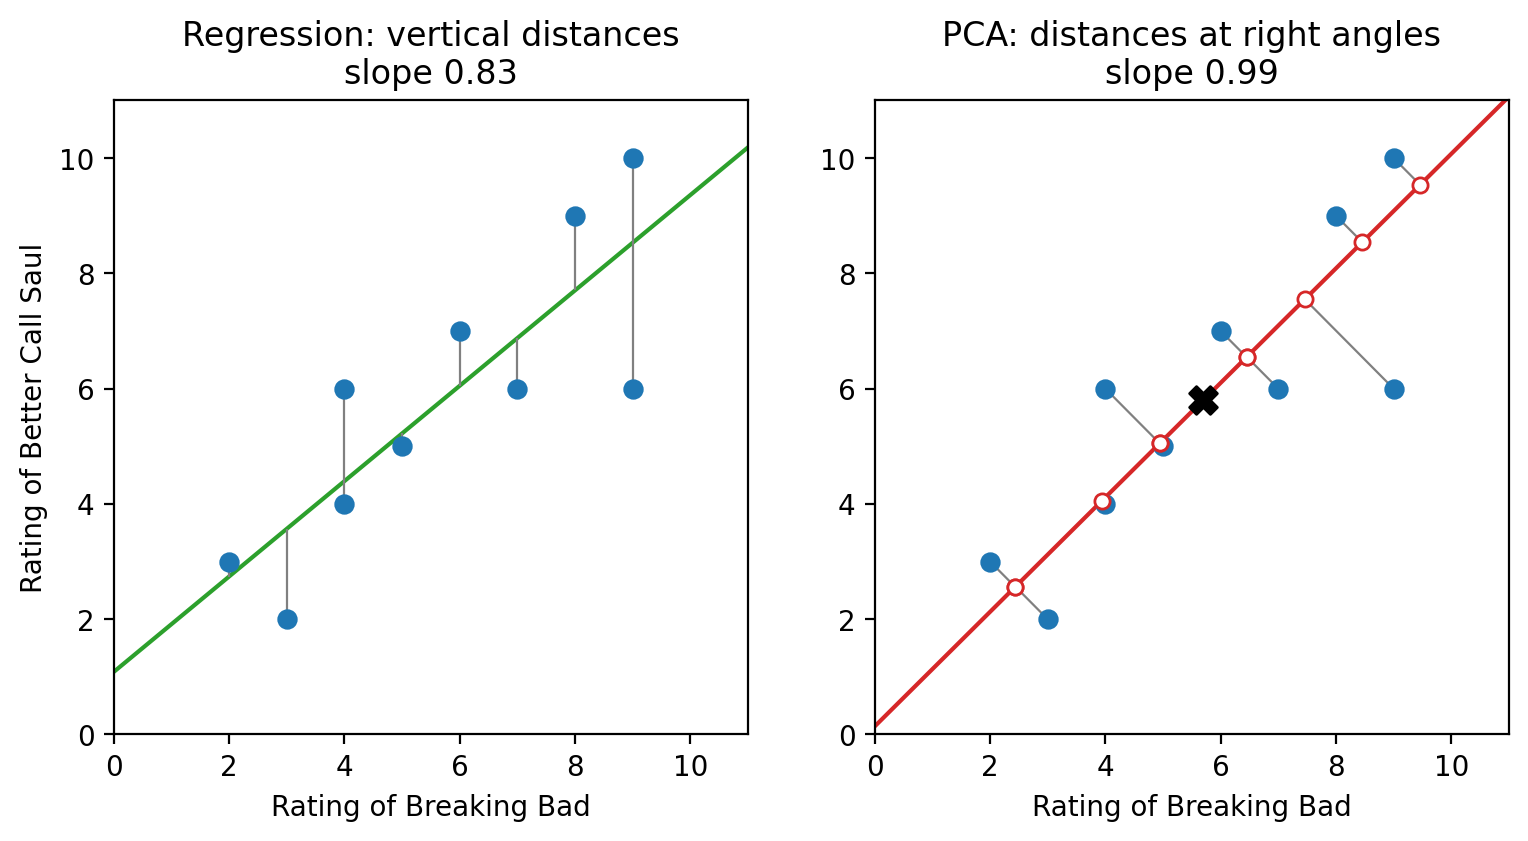

In [28]:
reg = LinearRegression().fit(shows[['breaking_bad']],
                             shows['better_call_saul'])
fitted = reg.predict(shows[['breaking_bad']])

fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))
xs = np.array([0, 11])
axes[0].plot(xs, reg.intercept_ + reg.coef_[0] * xs, color='C2', lw=1.5)
axes[0].vlines(X_shows[:, 0], fitted, X_shows[:, 1], color='gray',
               lw=0.8)
axes[0].scatter(X_shows[:, 0], X_shows[:, 1], s=40, color='C0',
                zorder=3)
show_axes(axes[0])
axes[0].set_title(f'Regression: vertical distances\n'
                  f'slope {reg.coef_[0]:.2f}')
draw_line(axes[1], unit(best), 'PCA: distances at right angles')
axes[1].set_title('PCA: distances at right angles\n'
                  f'slope {np.tan(np.radians(best)):.2f}')
axes[1].set_ylabel('')
plt.show()

### Rotate the axes to the two components

- The **second principal component** (PC2) is perpendicular to PC1. It
  explains as much as possible of the variance that PC1 leaves
  unexplained.

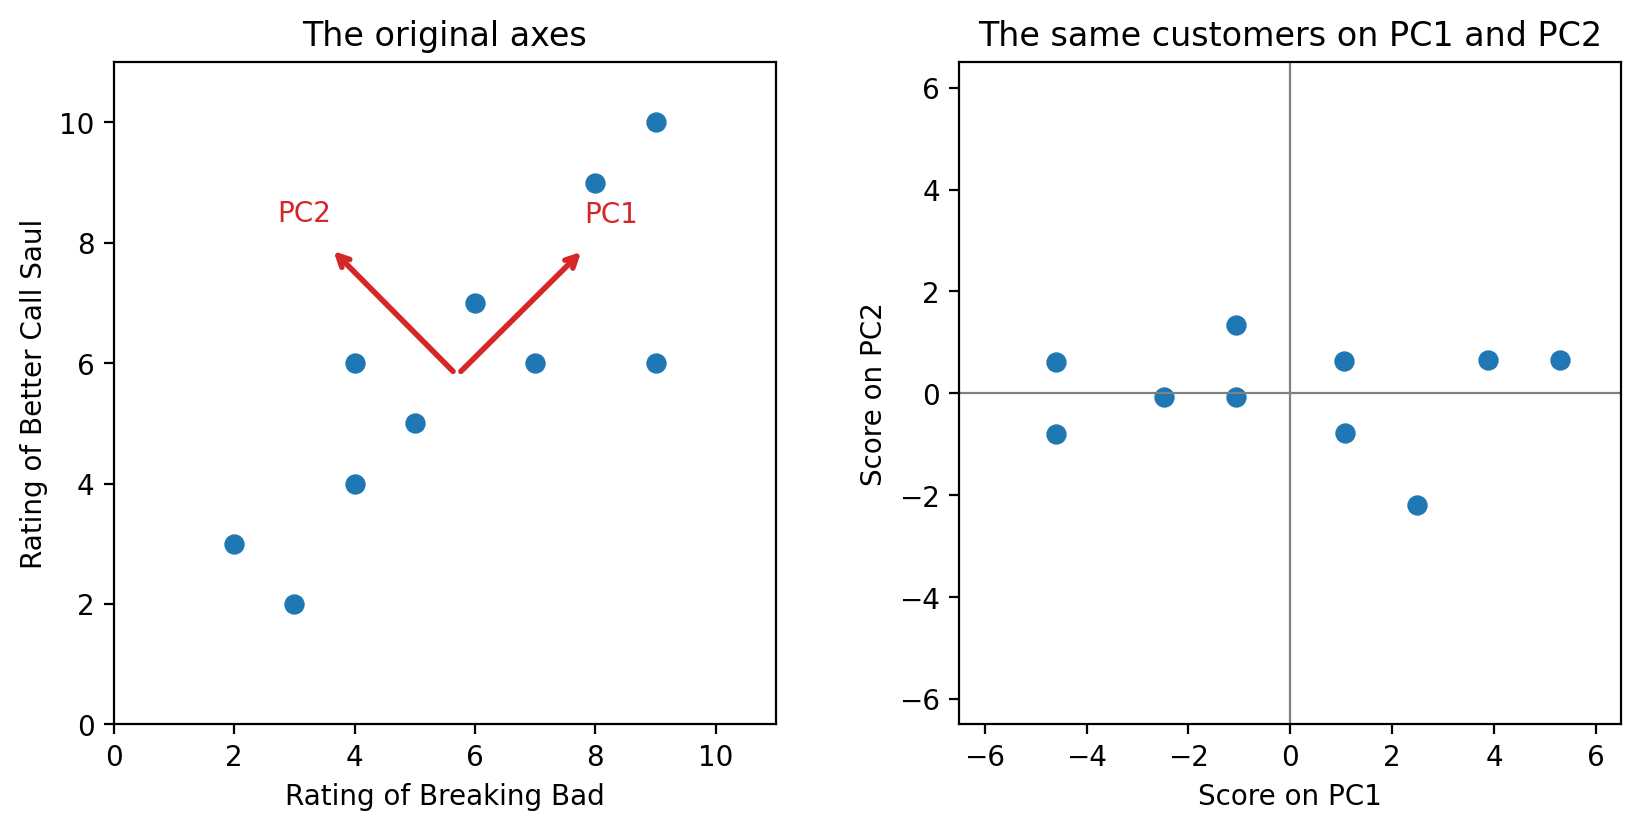

In [29]:
pc1_dir, pc2_dir = unit(best), unit(best + 90)
z1 = (X_shows - center) @ pc1_dir
z2 = (X_shows - center) @ pc2_dir

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
axes[0].scatter(X_shows[:, 0], X_shows[:, 1], s=40, color='C0')
for d, name in [(pc1_dir, 'PC1'), (pc2_dir, 'PC2')]:
    tip = center + 3 * d
    axes[0].annotate('', xy=tip, xytext=center,
                     arrowprops={'arrowstyle': '->', 'lw': 2,
                                 'color': 'C3'})
    axes[0].text(*(center + 3.6 * d), name, color='C3', ha='center')
show_axes(axes[0])
axes[0].set_title('The original axes')
axes[1].scatter(z1, z2, s=40, color='C0')
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].axvline(0, color='gray', lw=0.8)
axes[1].set(xlabel='Score on PC1', ylabel='Score on PC2',
            xlim=(-6.5, 6.5), ylim=(-6.5, 6.5), aspect='equal',
            title='The same customers on PC1 and PC2')
plt.show()

- In the right panel the long direction of the cloud is horizontal. The
  PC1 scores run from about $-5$ to $5$; the PC2 scores stay within 2.2
  of zero.
- Together the two scores explain all of the variance,
  $11.36 + 1.05 = 12.41$. PC1 alone explains $11.36 / 12.41$, or 91.5
  percent, with half as many numbers.

### Fit `PCA` on the ratings

`PCA` follows the same pattern as every `sklearn` model: create it, fit
it on `X` (there is no `y`), then read its attributes.

In [30]:
pca_shows = PCA(n_components=2, random_state=0)
pca_shows.fit(shows)
print(pca_shows.mean_)
print(pca_shows.components_.round(3))
print(pca_shows.explained_variance_.round(2))
print(pca_shows.explained_variance_ratio_.round(3))

[5.7 5.8]
[[ 0.709  0.705]
 [-0.705  0.709]]
[11.36  1.05]
[0.915 0.085]


- `mean_` is the center.
- `components_` has one row per component and one weight per column.
- `explained_variance_` is the variance each component explains: 11.36
  and 1.05, as in the figures.
- `explained_variance_ratio_` divides each by the total variance, 12.41:
  0.915 and 0.085.

The main output is the position of each open circle on the red line: one
number that summarizes a customer's ratings of both shows. That number is
the score on PC1, and `.fit_transform()` returns it. The first column
holds the scores on PC1, the second the scores on PC2.

In [31]:
scores_shows = pca_shows.fit_transform(shows)
shows.assign(pc1=scores_shows[:, 0],
             pc2=scores_shows[:, 1])

,breaking_bad,better_call_saul,pc1,pc2
0,2,3,-4.597892,0.624012
1,3,2,-4.594082,-0.790196
2,4,4,-2.474674,-0.077378
3,4,6,-1.064276,1.340641
4,5,5,-1.060466,-0.073568
5,6,7,1.058942,0.639251
6,7,6,1.062752,-0.774957
7,8,9,3.887359,0.646871
8,9,6,2.480770,-2.185356
9,9,10,5.301567,0.650681


- Each score is a weighted sum of the customer's centered ratings, with
  the weights in `components_`.
- Customer 8 (counting from 0) rated Breaking Bad 9 and Better Call Saul
  6. Their score is 2.48 on PC1, a fan of both shows, and $-2.19$ on PC2,
  the strongest preference for Breaking Bad among the ten.

### More columns, the same idea

- With $p$ columns, a component is a direction in $p$ dimensions, with
  one weight per column. PC1 is the direction that explains the most
  variance. PC2 is perpendicular to PC1 and explains the most of what is
  left. PC3 is perpendicular to both, and so on.
- The shares of all the components add up to 1. Plotted in order, they
  make a **scree plot**, which we read like the elbow plot of k-means.
- Scale matters. PCA follows variance, so a column measured in large
  units takes over PC1. When columns use different units, standardize
  them first with `StandardScaler`, as in lecture 13. A vote matrix holds
  only 0s and 1s and needs no scaling.
- `PCA` needs a dense array. A TF-IDF matrix from `TfidfVectorizer` is
  sparse, so call `.toarray()` on it first.

### `PCA`: what to write

| Goal | Write | Returns |
|---|---|---|
| Create the model | `pca = PCA(n_components=2, random_state=0)` | an unfitted model that computes the first 2 components |
| Fit and get the scores | `scores = pca.fit_transform(X)` | an array: one row per observation, one column per component |
| Scores for new observations | `pca.transform(X_new)` | the same shape |
| The center | `pca.mean_` | one number per column |
| The weights | `pca.components_` | one row per component, one column per original column |
| Variance each component explains | `pca.explained_variance_` | one variance per component |
| Each component's share | `pca.explained_variance_ratio_` | one share per component |
| A sparse TF-IDF matrix | `pca.fit_transform(tfidf.toarray())` | `.toarray()` makes it dense first |

## Part 5: PCA on the roll-call votes of the House

### The roll calls of the 118th House

- In Part 3, the two NOMINATE scores split the 2025 House into its two
  parties. Those scores summarize votes.
- From the votes alone, does PCA find the same left-to-right order as
  NOMINATE?
- The 118th House (2023 to 2024) is the most recent House whose term has
  ended, so the file holds all of its votes.
- [Voteview](https://voteview.com/data), the project that publishes
  NOMINATE, provides every recorded vote of every Congress. We saved
  these files on 2026-10-27 in `data/raw/voteview/`:

| File | One row is | Columns used today |
|---|---|---|
| `H118_votes.csv.gz` | one member's vote on one roll call | `icpsr` (member ID), `rollnumber`, `cast_code` |
| `HSall_members.csv.gz`| one member in one Congress | `icpsr`, `congress`, `chamber`, `bioname`, `state_abbrev`, `party_code`, `nominate_dim1`, `nominate_dim2` |
| `H118_rollcalls.csv` | one roll call | `rollnumber`, `date`, `bill_number`, `vote_question`, `vote_desc` |

### Read the votes: one row per member per roll call

The votes file is compressed with gzip; `read_csv` opens it directly.

In [32]:
votes = pd.read_csv(VOTEVIEW / 'H118_votes.csv.gz')
rollcalls = pd.read_csv(VOTEVIEW / 'H118_rollcalls.csv')
members = members_all[(members_all['congress'] == 118)
                      & (members_all['chamber'] == 'House')]
print(votes.shape)
votes.head(3)

(537213, 6)


,congress,chamber,rollnumber,icpsr,cast_code,prob
0,118,House,1,14854,6,100.0
1,118,House,1,14863,6,98.4
2,118,House,1,14873,1,100.0


In [33]:
votes['cast_code'].value_counts().sort_index()

cast_code
1    293577
6    223084
7       293
9     20259
Name: count, dtype: int64

- 537,213 rows: one per member per roll call, in long form.
- `cast_code` records the vote ([Voteview's codes](https://voteview.com/articles/data_help_votes)).
  In 2023 and 2024 only codes 1, 6, 7, and 9 occur:

| Code | Meaning |
|---|---|
| 1 | yea |
| 2, 3 | paired yea, announced yea: a stated yea, not cast |
| 4, 5 | announced nay, paired nay: a stated nay, not cast |
| 6 | nay |
| 7, 8 | present |
| 9 | not voting |

### Code each vote as 1, 0, or missing

PCA needs numbers. A yea or a stated yea becomes 1, and a nay or a
stated nay becomes 0. `.map` with a dictionary returns `NaN` for any code
the dictionary leaves out, so present and not voting become missing.

In [34]:
yea_or_nay = {1: 1, 2: 1, 3: 1, 4: 0, 5: 0, 6: 0}
votes['yea'] = votes['cast_code'].map(yea_or_nay)
votes['yea'].value_counts(dropna=False)

yea
1.0    293577
0.0    223084
NaN     20552
Name: count, dtype: int64

- 293,577 yeas, 223,084 nays, and 20,552 missing votes.

### Pivot to one row per member and one column per roll call

The votes file also records the positions of the president, Joe Biden,
on some roll calls. Keep only the House members, then pivot as in
lecture 7: `index` gives the rows, `columns` gives the columns, and
`values` fills the cells.

In [35]:
votes = votes[votes['icpsr'].isin(members['icpsr'])]
matrix = votes.pivot(index='icpsr', columns='rollnumber',
                     values='yea')
print(matrix.shape)
print(round(matrix.isna().mean().mean(), 3))
matrix.iloc[:5, :8]

(451, 1235)
0.073


rollnumber,1,2,3,4,5,6,7,8
icpsr,,,,,,,,
14854,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
14863,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
14873,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
15029,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
15433,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0


- 451 members by 1,235 roll calls; 7 percent of the cells are missing.
- Each row is now one member's voting record. That is the form PCA
  needs: one observation per row and one feature per column.

### Drop members with fewer than half the votes, fill the rest

Members who resigned, died, or arrived during the term missed many votes.
Keep the members who voted on at least half of the roll calls.

PCA cannot work with missing values, so fill each remaining missing vote
with the share of yeas on that roll call among the members who voted.

In [36]:
voted = matrix.notna().mean(axis=1)
dropped = voted.index[voted < 0.5]
print(members.set_index('icpsr').loc[dropped, 'bioname'].tolist())
matrix = matrix[voted >= 0.5]
filled = matrix.fillna(matrix.mean())
filled.shape

['MCCARTHY, Kevin', 'CICILLINE, David N.', 'STEWART, Chris', 'SUOZZI, Thomas', 'GONZÁLEZ-CÓLON, Jenniffer', 'NORTON, Eleanor Holmes', 'PLASKETT, Stacey E.', 'RADEWAGEN, Aumua Amata Coleman', 'SABLAN, Gregorio Kilili Camacho', 'MOYLAN, James', 'AMO, Gabe', 'MALOY, Celeste', 'KENNEDY, Timothy M.', 'FONG, Vince', 'RULLI, Michael A.', 'LOPEZ, Greg', 'MCIVER, LaMonica', 'LEE CARTER, Erica', 'WIED, Tony']


(432, 1235)

- 19 members leave. Kevin McCarthy seldom voted as Speaker and left the
  House at the end of 2023. Six members represent Washington, DC, and the
  territories. The rest left or arrived during the term. The matrix is
  now 432 members by 1,235 roll calls.
- The fill is an assumption. A filled value lies between 0 and 1, so it
  pulls the member toward neither side of that roll call. NOMINATE
  instead skips missing votes.

### Fit `PCA` and draw the share of the variance each component explains

Ten components are enough to see where the shares level off.
`random_state=0` fixes the random numbers that `PCA` uses on large
matrices, so every run gives the same scores.

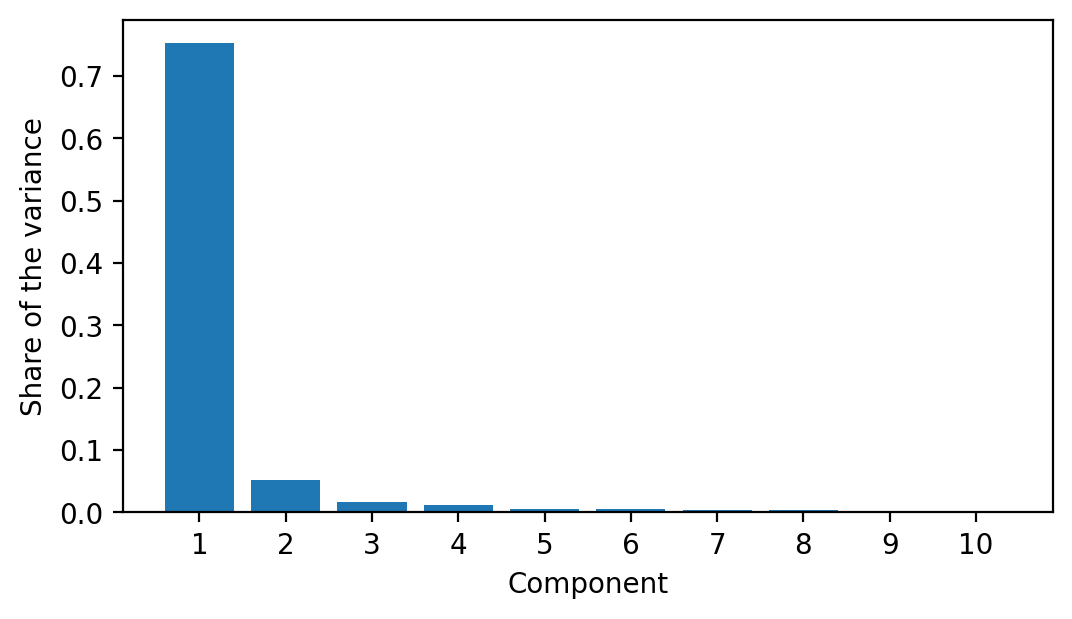

array([0.753, 0.051, 0.016, 0.012, 0.005, 0.005, 0.004, 0.004, 0.003,
       0.003])

In [37]:
pca = PCA(n_components=10, random_state=0)
scores = pca.fit_transform(filled)
shares = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(range(1, 11), shares)
ax.set(xlabel='Component', ylabel='Share of the variance',
       xticks=range(1, 11))
plt.show()
shares.round(3)

- PC1 explains 75 percent of the variance across the 1,235 columns, PC2
  explains 5 percent, and each later component 2 percent or less. The
  scree plot bends after the first component.
- One direction explains three quarters of the variance in this House's
  votes.

### Compare the first component with NOMINATE's first dimension

Put the PCA scores next to each member's party and NOMINATE scores.

In [38]:
house = members.set_index('icpsr').loc[filled.index].copy()
house['party'] = house['party_code'].map({100: 'Democrat',
                                           200: 'Republican'})
house['pc1'] = scores[:, 0]
house['pc2'] = scores[:, 1]
round(house['pc1'].corr(house['nominate_dim1']), 3)

-0.977

- The correlation is $-0.977$: nearly the same order, but with the
  Republicans on the negative side.
- The sign of a component is arbitrary: multiplying a component's scores
  and weights by $-1$ gives the same fit. Flip each component so that it
  runs the same way as the NOMINATE dimension it resembles, with
  Republicans on the positive side of the first.

In [39]:
sign1 = np.sign(house['pc1'].corr(house['nominate_dim1']))
sign2 = np.sign(house['pc2'].corr(house['nominate_dim2']))
house['pc1'] = sign1 * house['pc1']
house['pc2'] = sign2 * house['pc2']
weights = pd.DataFrame({'pc1_weights': sign1 * pca.components_[0],
                        'pc2_weights': sign2 * pca.components_[1]},
                       index=filled.columns)
print(sign1, sign2)

-1.0 1.0


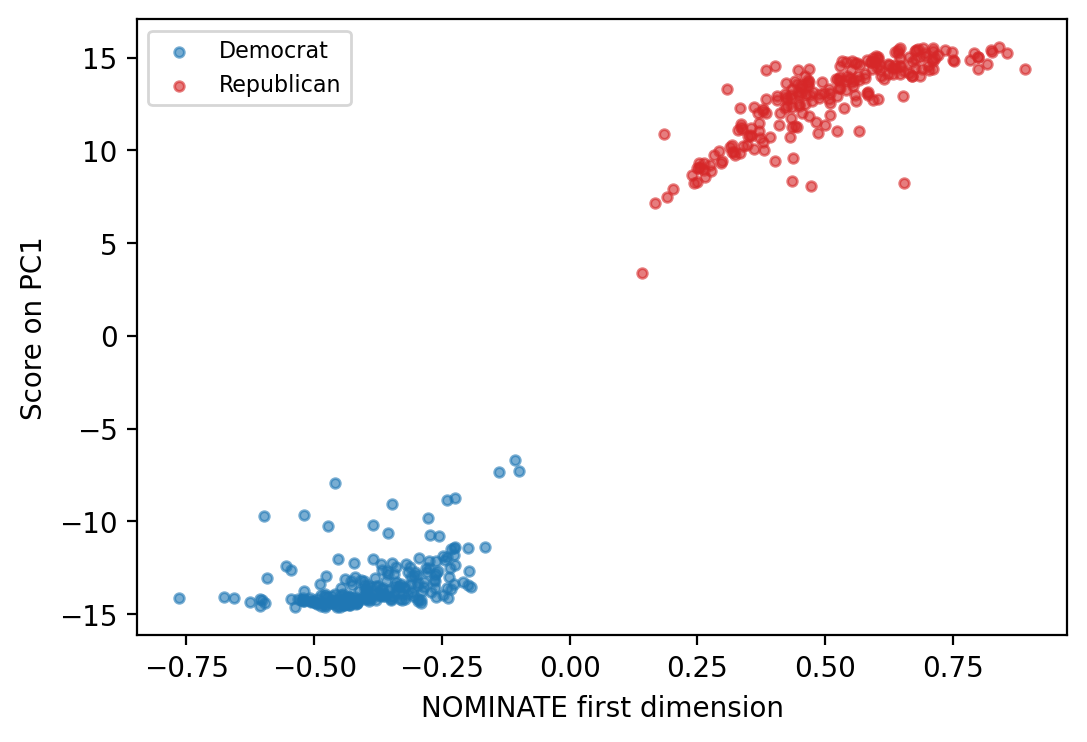

0.977

In [40]:
party_colors = {'Democrat': 'C0', 'Republican': 'C3'}

def party_scatter(ax, x, y):
    for party, color in party_colors.items():
        part = house[house['party'] == party]
        ax.scatter(part[x], part[y], s=12, color=color, alpha=0.6,
                   label=party)
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(6, 4))
party_scatter(ax, 'nominate_dim1', 'pc1')
ax.set(xlabel='NOMINATE first dimension', ylabel='Score on PC1')
plt.show()
round(house['pc1'].corr(house['nominate_dim1']), 3)

- After the flip, the correlation is 0.977.
- PCA never saw a party label or a NOMINATE score, yet it found nearly
  the same left-to-right order in the 0s and 1s.
- Most of the correlation comes from the gap between the parties. Within
  each party the order is looser: members who vote with their party on
  nearly every roll call pile up at the end of PC1.
- The match is not exact. NOMINATE fits a model of how members choose
  between yea and nay and skips missing votes; PCA fits straight
  directions to a filled matrix. Still, the two methods agree closely.

### Find the members closest to the other party on PC1

Circle the three Democrats with the highest PC1 scores and the three
Republicans with the lowest. Then list the three members of each party
that NOMINATE's first dimension places closest to the other party.

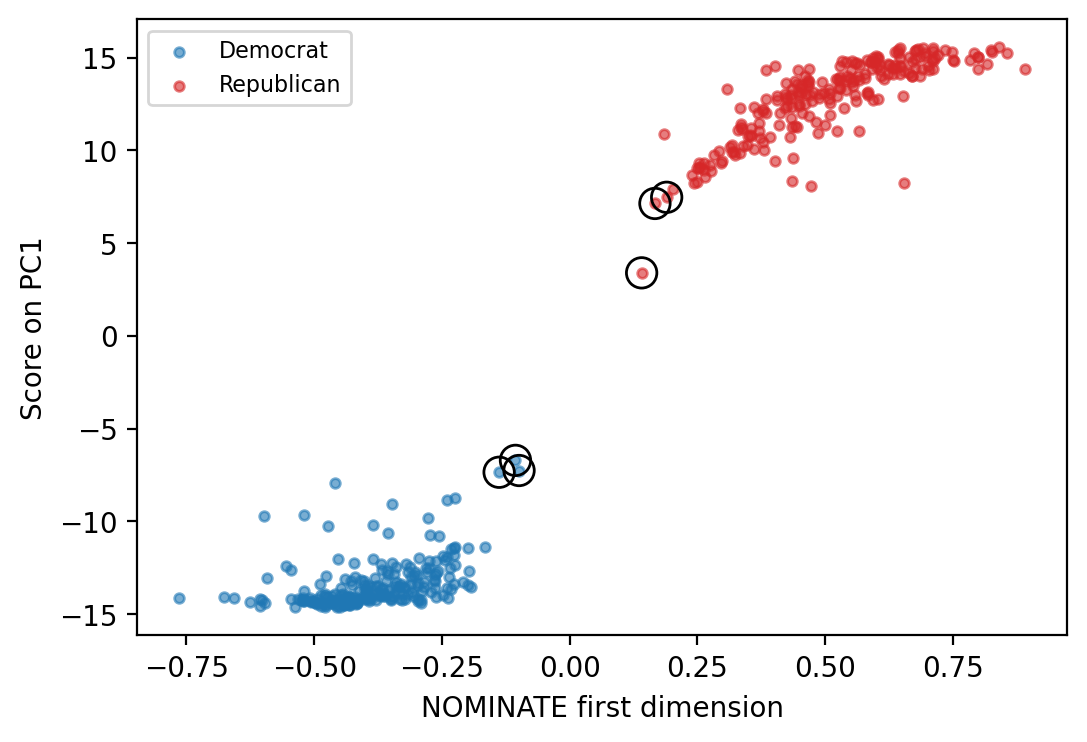

['PEREZ, Marie Gluesenkamp', 'GOLDEN, Jared', 'PELTOLA, Mary Sattler']
['FITZPATRICK, Brian K.', 'CHAVEZ-DEREMER, Lori', 'SMITH, Christopher Henry']


,bioname,state_abbrev,party,pc1,nominate_dim1
icpsr,,,,,
21923,"GOLDEN, Jared",ME,Democrat,-6.71,-0.11
22358,"PEREZ, Marie Gluesenkamp",WA,Democrat,-7.26,-0.10
22168,"PELTOLA, Mary Sattler",AK,Democrat,-7.35,-0.14
21718,"FITZPATRICK, Brian K.",PA,Republican,3.40,0.14
22308,"CHAVEZ-DEREMER, Lori",OR,Republican,7.14,0.17
22340,"LAWLER, Michael",NY,Republican,7.47,0.19


In [41]:
dems_118 = house[house['party'] == 'Democrat']
reps_118 = house[house['party'] == 'Republican']
inner = pd.concat([dems_118.nlargest(3, 'pc1'),
                   reps_118.nsmallest(3, 'pc1')])

fig, ax = plt.subplots(figsize=(6, 4))
party_scatter(ax, 'nominate_dim1', 'pc1')
ax.scatter(inner['nominate_dim1'], inner['pc1'], s=120,
           facecolors='none', edgecolors='black')
ax.set(xlabel='NOMINATE first dimension', ylabel='Score on PC1')
plt.show()
print(dems_118.nlargest(3, 'nominate_dim1')['bioname'].tolist())
print(reps_118.nsmallest(3, 'nominate_dim1')['bioname'].tolist())
columns = ['bioname', 'state_abbrev', 'party', 'pc1', 'nominate_dim1']
inner[columns].round(2)

- On PC1 the Democrats closest to the Republicans are Jared Golden of
  Maine, Marie Gluesenkamp Perez of Washington, and Mary Peltola of
  Alaska. The Republicans closest to the Democrats are Brian Fitzpatrick
  of Pennsylvania, Lori Chavez-DeRemer of Oregon, and Mike Lawler of New
  York. No member sits between $-6.7$ and 3.4.
- NOMINATE's first dimension names the same three Democrats and two of
  the same three Republicans. It puts Christopher Smith of New Jersey in
  place of Lawler.
- Gluesenkamp Perez and Fitzpatrick are the two members circled in Part
  3, on the NOMINATE scores of the 119th House. Here PCA finds them from
  the votes of the 118th House alone.

### Map the members on the first two components

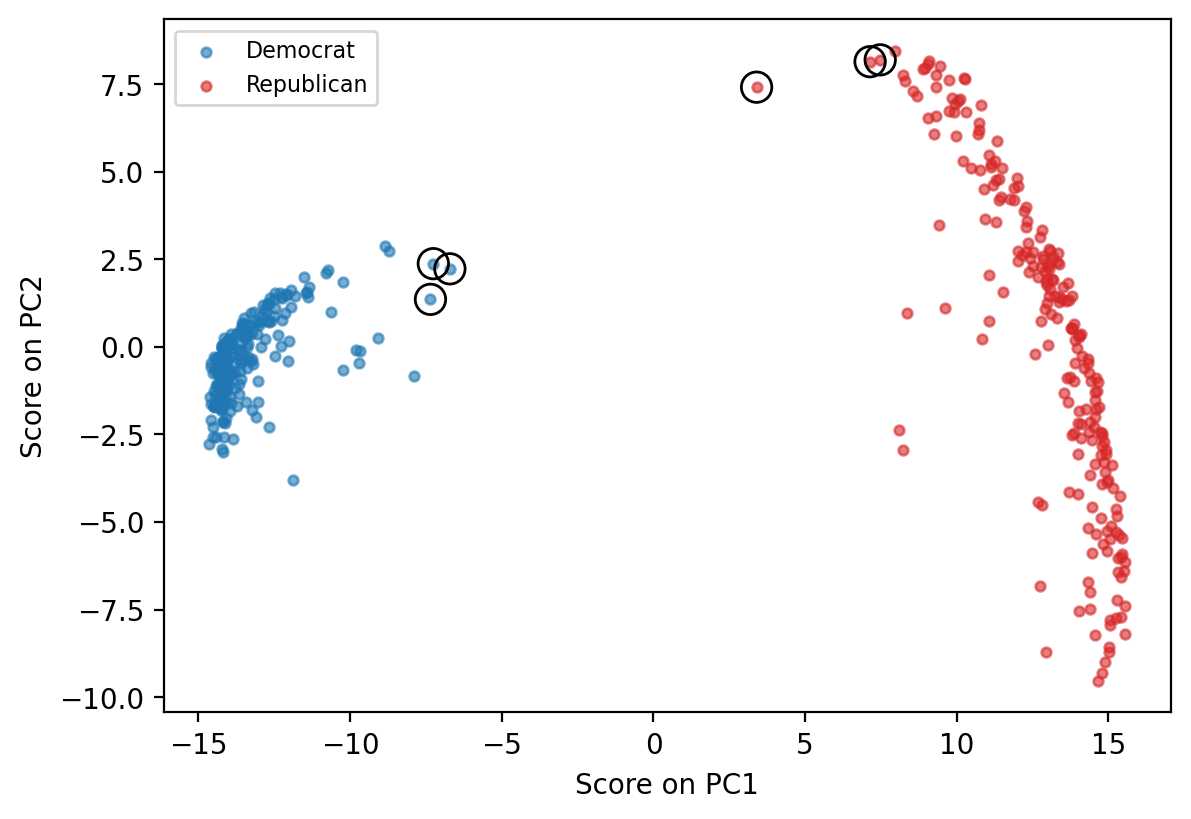

pc1         pc2      
             mean   std  mean   std
party                              
Democrat   -13.32  1.42 -0.29  1.19
Republican  12.84  2.14  0.28  4.69

In [42]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
party_scatter(ax, 'pc1', 'pc2')
ax.scatter(inner['pc1'], inner['pc2'], s=120, facecolors='none',
           edgecolors='black')
ax.set(xlabel='Score on PC1', ylabel='Score on PC2')
plt.show()
house.groupby('party')[['pc1', 'pc2']].agg(['mean', 'std']).round(2)

- The parties sit far apart on PC1 (means $-13.3$ and 12.8). On PC2 the
  Democrats spread little (standard deviation 1.2) and the Republicans
  spread a lot (4.7).

### Compare the second component with NOMINATE's second dimension

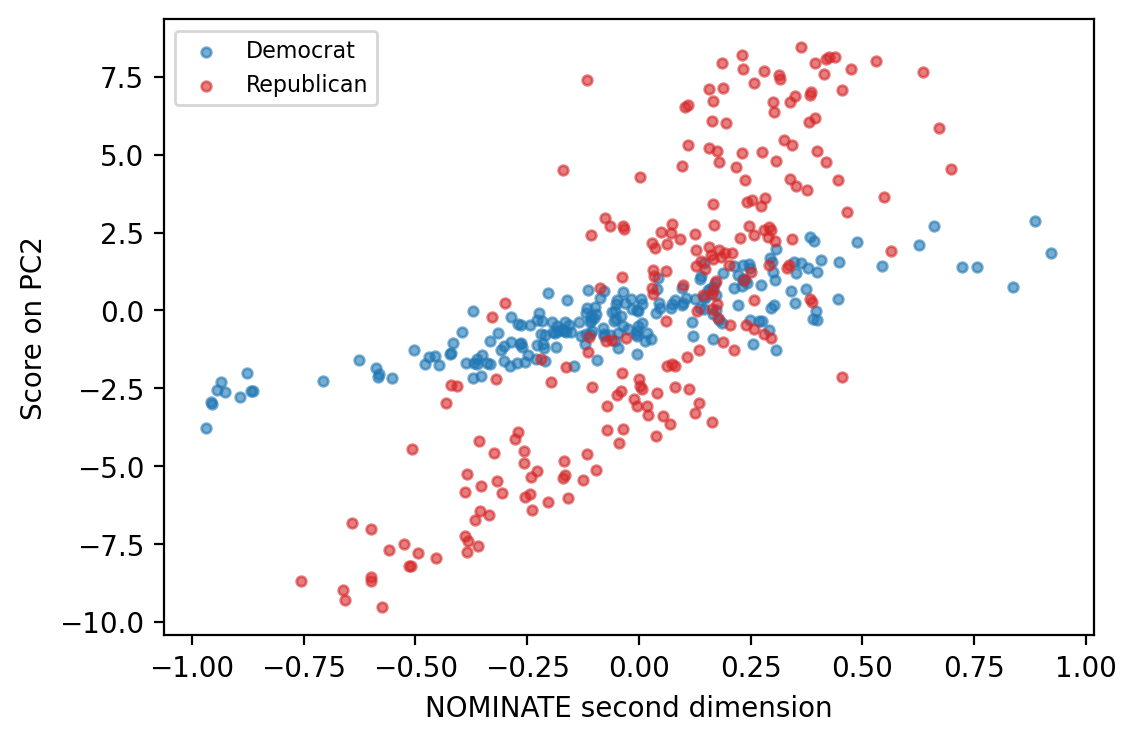

0.672

In [43]:
fig, ax = plt.subplots(figsize=(6, 4))
party_scatter(ax, 'nominate_dim2', 'pc2')
ax.set(xlabel='NOMINATE second dimension', ylabel='Score on PC2')
plt.show()
round(house['pc2'].corr(house['nominate_dim2']), 3)

- The correlation is 0.672, weaker than the 0.977 for PC1. The two
  scores rise together in both parties, but over the same range of
  NOMINATE's second dimension the Republicans spread much more on PC2
  than the Democrats.

### Read PC1 from the bills with the largest weights

- The weights show which roll calls a component follows. Amendments have
  no description in this file, so look at the votes on passing a bill:
  the roll calls whose `vote_question` contains `Pass`, whether a regular
  vote or under suspension of the rules. `vote_desc` holds the bill's
  title.
- Next to each bill, the share of each party that voted yea.

In [44]:
yea_share = filled.groupby(house['party']).mean().T.round(2)
print(house['party'].value_counts())

passage = rollcalls[rollcalls['vote_question'].str.contains('Pass')]
bills = passage.set_index('rollnumber')[['date', 'bill_number',
                                         'vote_desc']].copy()
bills['vote_desc'] = bills['vote_desc'].str[:40]
bills = bills.join(weights).join(yea_share)
len(bills)

party
Republican    220
Democrat      212
Name: count, dtype: int64


364

In [45]:
top1 = pd.concat([bills.nlargest(5, 'pc1_weights'),
                  bills.nsmallest(5, 'pc1_weights')])
top1.drop(columns='pc2_weights').round(3)

,date,bill_number,vote_desc,pc1_weights,Democrat,Republican
rollnumber,,,,,,
264,2023-06-14,HR277,REINS Act,0.037,0.01,1.00
24,2023-01-09,HR23,Family and Small Business Taxpayer Prote,0.037,0.01,1.00
99,2023-01-31,HR382,Pandemic is Over Act,0.037,0.01,1.00
270,2023-06-15,HR288,Separation of Powers Restoration Act,0.037,0.01,0.99
281,2023-06-21,HR3799,CHOICE Arrangement Act,0.037,0.01,1.00
502,2023-09-28,HR5692,Making supplemental appropriations for t,-0.022,1.00,0.46
869,2024-04-20,HR8035,Ukraine Security Supplemental Appropriat,-0.021,1.00,0.49
776,2024-02-29,HR7463,Extension of Continuing Appropriations a,-0.018,0.99,0.55
653,2023-11-14,HR6363,Further Continuing Appropriations and Ot,-0.017,0.99,0.58


- The file has 364 passage votes.
- Positive weights: bills the Republican majority passed on party lines,
  such as the REINS Act and the Pandemic is Over Act. Democrats voted yea
  at 1 percent and Republicans at 99 to 100 percent. All five have weight
  0.037.
- Negative weights: a supplemental spending bill of September 2023, aid
  to Ukraine (H.R. 8035), and three continuing appropriations (stopgap
  spending) bills. Nearly every Democrat voted yea, while the Republicans
  split, with 46 to 59 percent voting yea.
- The negative weights reach only $-0.022$, because no bill came to a
  passage vote with Democrats for it and Republicans against it. PC1 is
  the line between the parties.

### Repeat the steps for every House since 2013

Repeat the same steps for the 113th to the 119th House in a loop: read
the votes, keep the House members, code the votes, pivot, drop members
with fewer than half the votes, fill, and fit. `abs` removes the
arbitrary sign of each correlation.

In [46]:
rows = []
for number in range(113, 120):
    house_votes = pd.read_csv(VOTEVIEW / f'H{number}_votes.csv.gz')
    house_members = members_all[(members_all['congress'] == number)
                                & (members_all['chamber'] == 'House')]
    house_votes = house_votes[house_votes['icpsr']
                              .isin(house_members['icpsr'])].copy()
    house_votes['yea'] = house_votes['cast_code'].map(yea_or_nay)
    record = house_votes.pivot(index='icpsr', columns='rollnumber',
                               values='yea')
    record = record[record.notna().mean(axis=1) >= 0.5]
    model = PCA(n_components=2, random_state=0)
    first = model.fit_transform(record.fillna(record.mean()))[:, 0]
    dim1 = house_members.set_index('icpsr').loc[record.index,
                                                'nominate_dim1']
    rows.append({'congress': number,
                 'members': record.shape[0],
                 'roll_calls': record.shape[1],
                 'pc1_share': model.explained_variance_ratio_[0],
                 'pc2_share': model.explained_variance_ratio_[1],
                 'r_dim1': abs(np.corrcoef(first, dim1)[0, 1])})
pd.DataFrame(rows).round(3)

,congress,members,roll_calls,pc1_share,pc2_share,r_dim1
0,113,428,1202,0.719,0.025,0.967
1,114,433,1322,0.772,0.026,0.970
2,115,431,1207,0.776,0.029,0.965
3,116,432,952,0.776,0.029,0.973
4,117,431,996,0.775,0.051,0.974
5,118,432,1235,0.753,0.051,0.977
6,119,431,674,0.828,0.028,0.967


- In every House since 2013, PC1 explains 72 to 83 percent of the
  variance and correlates 0.96 or more with NOMINATE's first dimension.
  PC2 explains 2.5 to 5 percent. The 119th row uses votes through
  October 2026.
- One direction describes most of each of these Houses. That is why two
  clusters on the NOMINATE scores in Part 3 matched party for all 449
  members.
  Political scientists call a House whose parties sit far apart on one
  dimension **polarized**. The activity asks whether the House of 1947
  looked like this.

<div class="alert alert-info">

**Key idea.** PCA replaces many columns with a few directions that
explain the most variance. The scores place the observations, the
weights show which columns each direction follows, and the shares show
how much of the variance the components explain.

</div>

## What we found

- Three clusters on the TF-IDF weights of the Federalist Papers, fit
  from 1,000 starts, found the three writers: Jay alone, Hamilton's 51
  papers, and Madison's papers with all 12 disputed ones. The style words
  `upon` and `on` separate Hamilton's cluster from Madison's.
- Two clusters on the two NOMINATE scores put all 449 members of the
  119th House with their party. Party was never an input.
- PCA on the 1,235 roll calls of the 118th House, with no labels, found
  NOMINATE's first dimension (correlation 0.977) and the same members
  closest to the other party. PC1 explains 75 percent of the variance.
  At one end are bills the Republican majority passed on party lines; at
  the other, bills that nearly every Democrat backed while Republicans
  split.

### What these tools are for

- **Clustering** groups observations that have no label: types of voters
  from survey answers, groups of countries from indicators, kinds of
  documents. Check the clusters against labels the algorithm did not
  see. Refit with another $k$, seed, and set of features, and report what
  changed.
- **PCA** builds maps and indexes: an ideology score from roll calls, one
  index from a set of survey questions, or a few columns in place of
  thousands before clustering or regression. Report the share of the
  variance each component explains, and read the weights before naming a
  component.

Poole, K. T., and H. Rosenthal (1985). "A Spatial Model for Legislative
Roll Call Analysis." *American Journal of Political Science* 29(2):
357–384.

McCarty, N., K. T. Poole, and H. Rosenthal (2006). *Polarized America:
The Dance of Ideology and Unequal Riches.* MIT Press.

Lewis, J. B., K. Poole, H. Rosenthal, A. Boche, A. Rudkin, and L. Sonnet
(2026). *Voteview: Congressional Roll-Call Votes Database.*
<https://voteview.com/>

### What we learned: functions and methods

| Goal | Write |
|---|---|
| Fit $k$ clusters; get the labels | `KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)` |
| The centroids; the score | `.cluster_centers_`; `.inertia_` |
| The cluster of a new observation | `.predict(X_new)` |
| Compare with a hidden label | `pd.crosstab(label, cluster)` |
| A second score for $k$ | `silhouette_score(X, labels)` |
| Merge-based clusters | `AgglomerativeClustering(n_clusters=k, linkage=...)` |
| Long votes to a matrix | `votes.pivot(index=..., columns=..., values=...)` |
| Fill missing cells with the column mean | `matrix.fillna(matrix.mean())` |
| Scores on the components | `PCA(n_components=2, random_state=0).fit_transform(X)` |
| Weights; explained variance; shares | `.components_`; `.explained_variance_`; `.explained_variance_ratio_` |
| Keep the passage votes | `rollcalls[rollcalls['vote_question'].str.contains('Pass')]` |